# W2 · From exploratory analysis to credible validation

**Project:** Persistent overtime among fixed-term (*contrata*) staff of the Servicio de Salud Metropolitano Central (SSMC), September 2024 – August 2026
**Course:** Business Intelligence · Universidad del Desarrollo · Workshop 2 (continuation of W1 and C1)
**Group 01:** Alessandro Lavezzi · José Saavedra
**Repository:** https://github.com/josenaxo/Proyecto-Business · W2 version: tag `W2` (see Section G.3)

**Notebook map.** The notebook follows the W2 rubric letters. The validation checks (C) run **before** the revised EDA (B), because the EDA must use the validated dataset.

| Section | Content | Rubric |
|---|---|---|
| A | Continuity, feedback-to-action table, changes to conclusions | A |
| 1 | Loading and type conversion | — |
| C | Data dictionary, 9 programmatic checks, treatment log with row counts | C |
| B | Revised EDA: denominators, missingness, 4 figures, interpretation | B |
| D | Populations, coverage bias, reproducible 25% sample | D |
| E | Leakage audit | E |
| F | Train/validation/test design, train-only preprocessing, holdout robustness check | F |
| G | Management summary, AI-use disclosure, reproducibility | G |

**Companion notebooks:**
- `EDA.ipynb`: W1/C1, preserved unchanged.
- `EDA2.ipynb`: the same KPIs computed for all six Metropolitan health services; it is the source for the cross-service evidence summarised in B.6 and D.

**Labels used in the text.** *Observation* = what an output shows. *Assumption* = a choice the data cannot verify. *Limitation* = what the evidence cannot establish. *Recommendation* = managerial suggestion.

**Reproducibility.** Run top to bottom (Kernel → Restart & Run All); every random operation uses `SEED = 42`.

## A. Continuity with W1/C1 and response to feedback

### A.1 Same problem, KPI and unit of observation

| Element | Definition (unchanged from C1) |
|---|---|
| **Business problem** | Fixed-term staff of the SSMC receive overtime pay recurrently. This may hide permanent staffing needs and raises cost and fatigue risks |
| **Objective** | Reduce the structural dependence on overtime to cover permanent functions |
| **Business question** | Which staff groups and positions receive overtime persistently, and how much does it weigh in their gross pay? |
| **Main KPI** | **Overtime persistence rate** = persons paid overtime (day or night) in ≥ 75% of their payroll months / persons present in the payroll ≥ 12 months |
| **Complementary KPIs** | Overtime frequency = person-months with overtime / person-months; overtime weight = median of (overtime amount / gross pay) among person-months with overtime and gross pay > 0 |
| **Unit of observation** | **Person-month**: records of the same person (name) in the same month are summed. The persistence KPI is computed per **person** |
| **Intended decision** | The SSMC people-management units **prioritise which staff groups and positions should have their staffing reviewed first**, instead of sustaining recurrent overtime payments |
| **Window** | 24 monthly payroll files, September 2024 – August 2026 (Active Transparency) |

### A.2 Feedback-to-action table

*Source note.* No written instructor comments on W1 or C1 had been received when this notebook was prepared, so all entries are **self-audit** corrections. The brief allows this when fewer than three comments are available. Each entry is grounded in an output of this notebook or of `EDA2.ipynb`.

| # | Source | Issue found | Correction applied | Notebook evidence |
|---|---|---|---|---|
| F1 | Self-audit of C1 (KPI scope) | The persistence KPI was presented as describing "SSMC fixed-term staff", but its denominator keeps only 1,776 of 2,430 persons (73%). The 654 excluded persons differ: 24.0% of them ever received overtime, against 48.1% in the base | KPI re-labelled as "persons present ≥ 12 months". The excluded group is reported next to it and tenure is listed as a selection bias | B.1, B.2, D.2 |
| F2 | Self-audit of C1 (cleaning rules learned on all data) | The extreme-hours limit (157.5 h), the modal staff group/position and the persistence variable were computed on all 24 months. In the predictive task proposed in C1 §10 they would carry target-period information | Rules and attributes recomputed on year 1 only; preprocessing fitted on train only and refitted inside each CV fold | E.2 (R1–R4), F.1, F.3, F.4 |
| F3 | Self-audit of the EDA2 draft (loader) | The period was read as the last `_` token of the file name, so the Sur establishment files got periods such as `ServicioSur`. The common window collapsed to 2 months (16,470 of 201,952 rows), the persistence KPI was empty and Sur Oriente was not loaded | Period read with a regular expression; `establishment` column added; all six services loaded; common window of 22 months; an `assert` checks that the SSMC reproduces C1 | `EDA2.ipynb` §1.1 and §3.4; check C8 |
| F4 | Self-audit of the W1 parser and data dictionary | Amounts written with a decimal comma (`1.303.067,00`) became NaN. `Directivo` and `Indefinido` were undocumented. The C1 statement "the holiday-overtime column is empty" is true only for the SSMC: other services have 10,759 rows with holiday overtime | Parser fixed (2 Norte rows; 0 SSMC rows); dictionary extended; holiday overtime flagged as a limitation for cross-service comparisons | C.0, C2, C3e, C6a |
| F5 | Self-audit of C1 (interpretation) | C1 used causal wording ("overtime is the habitual way to cover functions"), reported rates without uncertainty and had no external benchmark, so "high" had no reference | Association wording; 95% Wilson intervals; benchmark against five services with direct standardisation | B.1, B.6, B.7, `EDA2.ipynb` §4 |
| F6 | Self-audit of C1 §9 (relationship claim) | "Where persistence is higher, overtime also weighs more" was not checked across positions | Checked: true within staff groups at person level (Spearman 0.57–0.70) but weak across staff-group × position segments (0.14). The claim is now restricted | B.4 |

### A.3 Changes to the original conclusions

| C1 conclusion | W2 status | What changed and why | Evidence |
|---|---|---|---|
| 20.5% (364 of 1,776) of SSMC contrata staff have persistent overtime | **Kept, re-scoped** | The value is unchanged after all checks (95% CI 18.7%–22.4%). It describes persons present ≥ 12 months, not all contrata staff. Short-tenure persons receive overtime less often, so a rate over all staff would be lower | B.1, D.2 |
| Persistence concentrates in auxiliary (55.4%) and administrative (44.8%) staff | **Kept, strengthened** | Same staff-group ordering in 24 of 24 months, in the year-2 holdout (test: 50.0% and 45.5%) and in all six Metropolitan services | B.5, F.5, B.6 |
| (Implicit in C1) the SSMC level signals an SSMC-specific problem | **Revised** | The SSMC is 3rd of 6 services (20.1% vs 16.7% network; 18.4% after standardising staff mix). Its level is not exceptional; its **intensity** is: the highest overtime weight in gross pay (14.6% vs 4.8%–12.4%) | B.6, `EDA2.ipynb` §3–4 |
| Where persistence is higher, overtime weighs more in pay | **Qualified** | Holds for persons within the same staff group (Spearman 0.57–0.70), not across segments (0.14): physicians have a high weight but rarely receive overtime | B.4 |
| Frequency fell from 28.4% to 26.4% in every staff group; it may reflect Dictamen E121666 | **Kept, re-interpreted** | The decline also appears in 5 of 6 services. This weakens SSMC-specific explanations, and a before/after comparison without an unexposed group still cannot identify the ruling's effect | B.5, `EDA2.ipynb` §6 |
| In these groups overtime is a habitual way to cover functions, so they are the first candidates for a staffing review | **Reworded** | They are where to **look first**. Persistence is an association with function and service; the cause (vacancies, shift design, authorisation practice) is not observable. Large differences between services within the same staff group suggest that organisation matters | B.7 |
| A future model could predict year-2 persistence from year-1 data (C1 §10) | **Kept, made operational** | The leakage audit identifies which C1 variables would leak. A person-grouped chronological split with train-only preprocessing is implemented; no model is fitted | E, F |

## 1. Loading and type conversion

Each file is read as text (`dtype=str`, `;` separator, latin-1 encoding), as in W1. The 21 source columns are renamed to short English names **by position**. This is only safe if every file has exactly the same header, so the loader stops with an error otherwise (check C1).

The period comes from the file name (`YYYY-MM`). The Sur service publishes one file per establishment, so the suffix after the period is kept as `establishment`. All six Metropolitan services are loaded:
- the analytical dataset is the SSMC (`ANALYSIS_SERVICE`);
- the other services are used only for coverage and representativeness (B.6, D).

In [1]:
import re
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: "%.3f" % x)

In [2]:
#CONFIGURATION
SEED = 42
DATA_DIR = Path("..") / "Data"

SERVICES = {                                   # file pattern of each Metropolitan health service
    "Centro": "TransparenciaActiva_*.csv",
    "Norte": "Norte_TransparenciaActiva_*.csv",
    "Oriente": "Oriente_TransparenciaActiva_*.csv",
    "Occidente": "Occidente_TransparenciaActiva_*.csv",
    "Sur": "Sur_TransparenciaActiva_*.csv",
    "SurOriente": "SurOriente_TransparenciaActiva_*.csv",
}
ANALYSIS_SERVICE = "Centro"                    # analytical dataset (W1/C1 business problem)
ESTABLISHMENT_ALIASES = {"HOSPITALDRLUCIOCORDOVA": "HospitalLucioCordova"}   # same hospital, two file names

PERSISTENCE_THRESHOLD = 75                     # % of payroll months with overtime
MIN_MONTHS = 12                                # months in payroll to enter the persistence denominator
ATYPICAL_MONTHS = ["2025-01"]                  # SSMC month with a different reporting format (W1 §4.3)
AMOUNT_MONTHS = ["2025-08"]                    # SSMC month whose amounts per hour are not comparable (C1 §8, EDA2 §3.2)
MIN_POSITION_PERSONS = 20                      # minimum persons for a position-level rate (C1 §9)

# Prediction design (Sections E-F)
FEATURE_START, FEATURE_END = "2024-09", "2025-08"   # information available at decision time (year 1)
TARGET_START, TARGET_END = "2025-09", "2026-08"     # period whose persistence would be predicted (year 2)
MIN_MONTHS_WINDOW = 6                               # months required in each window to be eligible
TEST_SIZE = 0.20
N_FOLDS = 5

C1_STAFF_GROUPS = ["Auxiliar", "Administrativo", "Técnico", "Profesional",
                   "Médicos cirujanos, farmacéuticos, químico-farmacéuticos, bioquímicos, cirujano-dentistas"]
STAFF_GROUP_EN = dict(zip(C1_STAFF_GROUPS, ["Auxiliary", "Administrative", "Technician", "Professional",
                                            "Physicians & related"]))
STAFF_GROUP_EN["Directivo"] = "Executive"      # found by check C6a; absent from the C1 dictionary
GROUP_ORDER = ["Auxiliary", "Administrative", "Technician", "Professional", "Physicians & related"]
GROUP_COLOR = dict(zip(GROUP_ORDER, ["#08519c", "#3182bd", "#6baed6", "#fd8d3c", "#a63603"]))

In [3]:
#LOADING ALL SERVICES
RAW_NAMES = [
    "year", "month_name", "staff_group", "name", "position", "grade", "qualification", "region",
    "special_allowances", "gross_pay_txt", "net_pay_txt", "additional_pay_txt", "bonus_txt",
    "ot_entitled", "ot_day_txt", "ot_night_txt", "ot_holiday_txt", "start_date_txt", "end_date_txt",
    "travel_allowance", "remarks",
]
PERIOD_RE = re.compile(r"\d{4}-\d{2}")

frames, files_log, reference_header = [], [], None
for service, pattern in SERVICES.items():
    for f in sorted(DATA_DIR.glob(pattern)):
        t = pd.read_csv(f, sep=";", encoding="latin-1", dtype=str)
        period = PERIOD_RE.search(f.stem).group()
        suffix = f.stem.split(period)[-1].strip("_")
        unnamed = [c for c in t.columns if c.startswith("Unnamed")]
        header = [c for c in t.columns if c not in unnamed]
        reference_header = reference_header or header
        files_log.append({
            "service": service, "file": f.name, "period": period,
            "establishment": ESTABLISHMENT_ALIASES.get(suffix, suffix) or service,
            "rows": len(t), "same_header": header == reference_header,
            "n_unnamed": len(unnamed), "unnamed_empty": bool(t[unnamed].isna().all().all()),
        })
        if header != reference_header:
            raise ValueError(f"{f.name}: header differs from the reference file; renaming by position is unsafe")
        t = t.drop(columns=unnamed)
        t.columns = RAW_NAMES
        t.insert(0, "service", service)
        t["period"] = period
        t["establishment"] = files_log[-1]["establishment"]
        t["source_file"] = f.name
        frames.append(t)

raw = pd.concat(frames, ignore_index=True)
files_log = pd.DataFrame(files_log)
print("Files read:", len(files_log), "| rows:", len(raw), "| sum of file rows:", files_log["rows"].sum())
files_log.groupby("service").agg(files=("file", "size"), first=("period", "min"), last=("period", "max"),
                                 months=("period", "nunique"), rows=("rows", "sum")).reindex(SERVICES)

Files read: 209 | rows: 246732 | sum of file rows: 246732


,files,first,last,months,rows
service,,,,,
Centro,24,2024-09,2026-08,24,44777
Norte,25,2024-09,2026-09,25,15790
Oriente,25,2024-09,2026-09,25,47260
Occidente,25,2024-09,2026-09,25,54995
Sur,85,2024-11,2026-09,23,39130
SurOriente,25,2024-09,2026-09,25,44780


In [4]:
#TYPE CONVERSION (SAME RULES AS W1 §2; DECIMAL COMMA HANDLED, SEE CHECK C2)
def to_amount(s):
    # "$ 1.234.567" -> 1234567; a decimal comma ("1.303.067,00") is read as a decimal point
    clean = (s.astype(str).str.replace("$", "", regex=False).str.strip()
              .str.replace(".", "", regex=False).str.replace(",", ".", regex=False))
    return pd.to_numeric(clean, errors="coerce").astype(float)

def split_overtime(s):
    txt = s.str.strip()
    none = txt.eq("No tiene")                                      # "No tiene" = no overtime of that type -> 0
    parts = txt.str.split(":", n=1, expand=True).reindex(columns=[0, 1])
    amount = to_amount(parts[0])
    hours = pd.to_numeric(parts[1].astype(str).str.replace("hrs", "", regex=False)
                                   .str.replace(".", "", regex=False)
                                   .str.replace(",", ".", regex=False).str.strip(),
                          errors="coerce").astype(float)
    return amount.where(~none, 0.0), hours.where(~none, 0.0)

payroll = raw.copy()
for txt_col, col in {"gross_pay_txt": "gross_pay", "net_pay_txt": "net_pay",
                     "additional_pay_txt": "additional_pay", "bonus_txt": "bonus"}.items():
    payroll[col] = to_amount(payroll[txt_col])
for kind in ["day", "night", "holiday"]:
    payroll[f"ot_{kind}_amount"], payroll[f"ot_{kind}_hours"] = split_overtime(payroll[f"ot_{kind}_txt"])
for txt_col, col in {"start_date_txt": "start_date", "end_date_txt": "end_date"}.items():
    payroll[col] = pd.to_datetime(payroll[txt_col], format="%d/%m/%Y", errors="coerce")

payroll["ot_amount"] = payroll[["ot_day_amount", "ot_night_amount"]].sum(axis=1)
payroll["ot_hours"] = payroll[["ot_day_hours", "ot_night_hours"]].sum(axis=1)
payroll["position_norm"] = payroll["position"].str.strip().str.upper().replace({"CHOFER": "CONDUCTOR"})
payroll["staff_group_en"] = payroll["staff_group"].str.strip().map(STAFF_GROUP_EN)
payroll["person_id"] = pd.factorize(payroll["service"] + "|" + payroll["name"].str.strip())[0] + 1   # names are not displayed
print("Rows:", len(payroll))

Rows: 246732


## C. Data validation

### C.0 Data dictionary

Following Class 4, each important variable has a valid domain $\mathcal A_j$, and a record is valid for that variable when $V_{ij} = I(X_{ij} \in \mathcal A_j) = 1$. A violation is a **flag**, not an automatic deletion.

| Variable (source column) | Expected type | Acceptable values | Missing-value meaning |
|---|---|---|---|
| `period` (file name) | text `YYYY-MM` | 2024-09 … 2026-09, one value per file | Never missing (taken from the file name) |
| `year`, `month_name` (Año, Mes) | integer / Spanish month name | Must match `period` | Not expected |
| `name` (Nombre completo) | text | Non-blank; the only person identifier (no national ID, RUT) | A blank name cannot be linked to a person |
| `staff_group` (Estamento) | category | Auxiliar, Administrativo, Técnico, Profesional, Médicos cirujanos…; **Directivo** (Executive, added in W2) | Not expected |
| `position` (Cargo o función) | free text | Normalised: upper case, CHOFER = CONDUCTOR | Not expected |
| `grade` (Grado EUS o jornada) | mixed text | EUS grade (number) or weekly hours ("44 Hrs.") | Not expected |
| `ot_entitled` (Derecho a horas extraordinarias) | category | Sí / No | Not expected |
| `gross_pay` (Remuneración bruta…) | CLP, number | ≥ 0; includes overtime, bonuses and allowances | `-` would mean "not reported" |
| `bonus`, `additional_pay` | CLP, number | ≥ 0 | `-` = not reported (whole-month pattern, likely MNAR, C1 §6.1); **not** imputed as 0 |
| `ot_day_*`, `ot_night_*`, `ot_holiday_*` (Montos y horas extraordinarias…) | `"$ amount : hours hrs"` → two numbers | amount ≥ 0 (a decimal comma may appear); 0 ≤ hours ≤ 744 (hours in a 31-day month); `No tiene` = 0 | Not expected |
| `ot_amount`, `ot_hours` (derived) | CLP / hours | Day + night (holiday excluded, as in C1); amount ≤ gross pay (gross pay includes it) | — |
| `start_date`, `end_date` (Fecha de inicio / término) | date `dd/mm/yyyy` (the header says `aa`, the values use four digits) | start ≤ end; the contract should overlap the payment month; `Indefinido` = open-ended contract (structural missing end date) | Not expected for start |
| `establishment` (file name, Sur only) | category | Hospital or service-level file | — |

### C.1–C.9 Programmatic checks

Each check records the rows tested, the failures and the action taken: **corrected**, **retained with justification** or **flagged as a limitation**. No row is deleted in this section. Checks run on all services; the SSMC column is the one that affects the KPIs.

In [5]:
#CHECK LOG
checks = []
def log_check(check_id, check, scope, tested, failures, action, ssmc_failures=None):
    checks.append({"id": check_id, "check": check, "scope": scope, "rows_tested": int(tested),
                   "failures": int(failures), "failure_%": failures / tested * 100 if tested else np.nan,
                   "ssmc_failures": np.nan if ssmc_failures is None else int(ssmc_failures), "action": action})

is_ssmc = payroll["service"] == ANALYSIS_SERVICE

# C1 · Schema
print("Files with a header different from the reference:", (~files_log["same_header"]).sum())
print("Files whose trailing unnamed column is not empty:", (~files_log["unnamed_empty"]).sum())
log_check("C1", "Same 21-column header in every file; trailing column empty", "all files",
          len(files_log), (~files_log["same_header"] | ~files_log["unnamed_empty"]).sum(),
          "Corrected: empty trailing column dropped; loader stops if a header differs")

Files with a header different from the reference: 0
Files whose trailing unnamed column is not empty: 0


In [6]:
#C2 · TYPE CONVERSION AND CODED MISSING VALUES
CODED = ["-", "Indefinido"]
conversion = []
for txt_col, col in {"gross_pay_txt": "gross_pay", "net_pay_txt": "net_pay", "additional_pay_txt": "additional_pay",
                     "bonus_txt": "bonus", "start_date_txt": "start_date", "end_date_txt": "end_date"}.items():
    txt = payroll[txt_col].str.strip()
    failed = payroll[col].isna() & txt.notna() & ~txt.isin(CODED)
    conversion.append({"variable": col, "blank": txt.isna().sum(), 'coded "-"': txt.eq("-").sum(),
                       'coded "Indefinido"': txt.eq("Indefinido").sum(), "not_convertible": failed.sum(),
                       "ssmc_coded": (txt.isin(CODED) & is_ssmc).sum()})
for kind in ["day", "night", "holiday"]:
    failed = (payroll[f"ot_{kind}_amount"].isna() | payroll[f"ot_{kind}_hours"].isna()) & payroll[f"ot_{kind}_txt"].notna()
    conversion.append({"variable": f"ot_{kind}", "blank": payroll[f"ot_{kind}_txt"].isna().sum(), 'coded "-"': 0,
                       'coded "Indefinido"': 0, "not_convertible": failed.sum(), "ssmc_coded": 0})
conversion = pd.DataFrame(conversion).set_index("variable")
display(conversion)

amount_parts = pd.concat([payroll[c].str.split(":").str[0] for c in ["ot_day_txt", "ot_night_txt", "ot_holiday_txt"]]
                         + [payroll[c] for c in ["gross_pay_txt", "net_pay_txt", "additional_pay_txt", "bonus_txt"]], axis=1)
decimal_comma = amount_parts.apply(lambda s: s.str.contains(r"\d,\d", regex=True)).any(axis=1)   # hours legitimately use "40,00"
print("Rows whose amounts use a decimal comma (lost by the W1 parser, now read):", decimal_comma.sum(),
      "| in the SSMC:", (decimal_comma & is_ssmc).sum())

print('Share of "-" in bonuses by service and month (%):')
display((payroll["bonus_txt"].str.strip().eq("-")
         .groupby([payroll["period"], payroll["service"]]).mean().unstack().reindex(columns=SERVICES) * 100).round(0))

log_check("C2", "Amounts, overtime and dates convertible (coded values excluded)", "all rows",
          len(payroll), conversion["not_convertible"].sum(),
          f'Corrected: decimal comma parsed ({decimal_comma.sum()} rows, Norte); "-" and "Indefinido" kept as '
          'missing (NaN/NaT), not imputed (possible MNAR, C1 §6.1)',
          ssmc_failures=0)

,blank,"coded ""-""","coded ""Indefinido""",not_convertible,ssmc_coded
variable,,,,,
gross_pay,0,0,0,0,0
net_pay,0,15434,0,0,0
additional_pay,0,82148,0,0,1825
bonus,0,71321,0,0,3065
start_date,0,0,0,0,0
end_date,0,0,355,0,0
ot_day,0,0,0,0,0
ot_night,0,0,0,0,0
ot_holiday,0,0,0,0,0


Rows whose amounts use a decimal comma (lost by the W1 parser, now read): 2 | in the SSMC: 0
Share of "-" in bonuses by service and month (%):


service,Centro,Norte,Oriente,Occidente,Sur,SurOriente
period,,,,,,
2024-09,0.000,29.000,62.000,0.000,NaN,100.000
2024-10,0.000,29.000,36.000,100.000,NaN,100.000
2024-11,0.000,29.000,0.000,100.000,0.000,100.000
2024-12,4.000,29.000,0.000,0.000,0.000,100.000
2025-01,0.000,29.000,0.000,0.000,0.000,100.000
2025-02,0.000,30.000,0.000,0.000,0.000,100.000
2025-03,0.000,30.000,0.000,0.000,0.000,100.000
2025-04,0.000,28.000,0.000,0.000,0.000,100.000
2025-05,80.000,27.000,100.000,0.000,0.000,100.000


In [7]:
#C3 · ALLOWED RANGES
rng = pd.DataFrame({
    "negative_gross_pay": payroll["gross_pay"] < 0,
    "zero_gross_pay": payroll["gross_pay"] == 0,
    "negative_ot_hours": payroll[["ot_day_hours", "ot_night_hours", "ot_holiday_hours"]].lt(0).any(axis=1),
    "ot_hours_above_744": payroll["ot_hours"] > 744,
    "ot_amount_above_gross_pay": payroll["ot_amount"] > payroll["gross_pay"],
    "holiday_ot_paid": payroll["ot_holiday_hours"] > 0,
})
display(rng.groupby(payroll["service"]).sum().reindex(SERVICES))

log_check("C3a", "Gross pay ≥ 0", "all rows", len(payroll), rng["negative_gross_pay"].sum(),
          "Retained: no negative values found", rng.loc[is_ssmc, "negative_gross_pay"].sum())
log_check("C3b", "Gross pay > 0 (denominator of the OT-weight KPI)", "all rows", len(payroll), rng["zero_gross_pay"].sum(),
          "Retained, flagged (flag_zero_pay): excluded only from the OT-weight KPI (structural missing)",
          rng.loc[is_ssmc, "zero_gross_pay"].sum())
log_check("C3c", "0 ≤ overtime hours ≤ 744 per contract-month", "all rows", len(payroll),
          (rng["negative_ot_hours"] | rng["ot_hours_above_744"]).sum(), "Retained: no values outside the range",
          (rng["negative_ot_hours"] | rng["ot_hours_above_744"])[is_ssmc].sum())
log_check("C3d", "Overtime amount ≤ gross pay", "all rows", len(payroll), rng["ot_amount_above_gross_pay"].sum(),
          "Retained, flagged (flag_impossible); C1 §6.4 shows the KPIs move < 0.2 points without them",
          rng.loc[is_ssmc, "ot_amount_above_gross_pay"].sum())
log_check("C3e", "Holiday overtime column empty (C1 assumption)", "all rows", len(payroll), rng["holiday_ot_paid"].sum(),
          "Flagged as limitation: holds in the SSMC only; other services pay holiday OT, which the C1 KPI excludes",
          rng.loc[is_ssmc, "holiday_ot_paid"].sum())

,negative_gross_pay,zero_gross_pay,negative_ot_hours,ot_hours_above_744,ot_amount_above_gross_pay,holiday_ot_paid
service,,,,,,
Centro,0,191,0,0,12,0
Norte,0,55,0,0,1,438
Oriente,0,99,0,0,14,1733
Occidente,0,2527,0,0,343,334
Sur,0,648,0,0,167,0
SurOriente,0,5,0,0,0,8254


In [8]:
#C4 · DATE LOGIC AND PERIOD CONSISTENCY
MONTHS_ES = {"enero": 1, "febrero": 2, "marzo": 3, "abril": 4, "mayo": 5, "junio": 6, "julio": 7, "agosto": 8,
             "septiembre": 9, "setiembre": 9, "octubre": 10, "noviembre": 11, "diciembre": 12}
period_start = pd.to_datetime(payroll["period"] + "-01")
period_end = period_start + pd.offsets.MonthEnd(0)

dates = pd.DataFrame({
    "start_after_end": payroll["start_date"] > payroll["end_date"],
    "contract_outside_payment_month": (payroll["end_date"] < period_start) | (payroll["start_date"] > period_end),
    "year_differs_from_file": payroll["year"].str.strip() != payroll["period"].str[:4],
    "month_differs_from_file": payroll["month_name"].str.strip().str.lower().map(MONTHS_ES) != period_start.dt.month,
})
display(dates.groupby(payroll["service"]).sum().reindex(SERVICES))
outside_ot = dates["contract_outside_payment_month"] & (payroll["ot_hours"] > 0)
print("SSMC contract rows outside the payment month that carry overtime:", (outside_ot & is_ssmc).sum())

log_check("C4a", "Start date ≤ end date", "all rows", len(payroll), dates["start_after_end"].sum(),
          "Retained: no failures; dates are not used in the KPIs", dates.loc[is_ssmc, "start_after_end"].sum())
log_check("C4b", "Contract overlaps the payment month", "all rows", len(payroll), dates["contract_outside_payment_month"].sum(),
          "Retained, flagged: payments can regularise past months (payment month ≠ work month)",
          dates.loc[is_ssmc, "contract_outside_payment_month"].sum())
log_check("C4c", "Año/Mes columns match the file period", "all rows", len(payroll),
          (dates["year_differs_from_file"] | dates["month_differs_from_file"]).sum(),
          "Corrected: the file period is used as the reference",
          (dates["year_differs_from_file"] | dates["month_differs_from_file"])[is_ssmc].sum())

,start_after_end,contract_outside_payment_month,year_differs_from_file,month_differs_from_file
service,,,,
Centro,0,90,0,0
Norte,0,154,5,1
Oriente,0,134,0,0
Occidente,0,42,0,317
Sur,0,0,0,0
SurOriente,0,700,0,0


SSMC contract rows outside the payment month that carry overtime: 59


In [9]:
#C5 · DUPLICATES AND KEY UNIQUENESS
key_cols = ["service", "period"] + RAW_NAMES          # all source columns (establishment and file name excluded)
exact_dup = payroll.duplicated(subset=key_cols)
records_per_key = payroll.groupby(["service", "period", "person_id"]).size()

dup = pd.DataFrame({
    "exact_duplicate_copies": exact_dup.groupby(payroll["service"]).sum(),
    "duplicates_with_overtime": (exact_dup & (payroll["ot_hours"] > 0)).groupby(payroll["service"]).sum(),
    "person_months": records_per_key.groupby("service").size(),
    "person_months_with_>1_record": (records_per_key > 1).groupby("service").sum(),
    "max_records_in_a_person_month": records_per_key.groupby("service").max(),
}).reindex(SERVICES)
display(dup)

log_check("C5a", "Exact duplicate rows", "all rows", len(payroll), exact_dup.sum(),
          "Retained with justification: SSMC physicians' hourly appointments without overtime (C1 §6.1)",
          exact_dup[is_ssmc].sum())
log_check("C5b", "(service, period, name) is unique", "all rows", len(payroll), (records_per_key > 1).sum(),
          "Corrected: unit of analysis is the person-month (records summed by person and month)",
          dup.loc[ANALYSIS_SERVICE, "person_months_with_>1_record"])

,exact_duplicate_copies,duplicates_with_overtime,person_months,person_months_with_>1_record,max_records_in_a_person_month
service,,,,,
Centro,27,0,43120,1507,6
Norte,0,0,15582,208,2
Oriente,0,0,46178,1031,4
Occidente,0,0,51128,3288,7
Sur,0,0,37471,1538,5
SurOriente,0,0,44434,331,3


In [10]:
#C6 · CATEGORY CONSISTENCY AND MISSING IDENTIFIERS
staff = payroll["staff_group"].str.strip()
cats = pd.DataFrame({
    "staff_group_not_in_C1_dictionary": ~staff.isin(C1_STAFF_GROUPS),
    "staff_group_unmapped_after_W2": payroll["staff_group_en"].isna(),
    "ot_entitled_not_si_no": ~payroll["ot_entitled"].str.strip().isin(["Sí", "No"]),
    "ot_paid_without_entitlement": (payroll["ot_hours"] > 0) & payroll["ot_entitled"].str.strip().eq("No"),
    "blank_name": payroll["name"].isna() | payroll["name"].str.strip().eq(""),
})
display(cats.groupby(payroll["service"]).sum().reindex(SERVICES))
print("Staff-group values outside the C1 dictionary:", staff[cats["staff_group_not_in_C1_dictionary"]].value_counts().to_dict())
print("Distinct regions:", payroll["region"].nunique(), "| distinct positions (raw / normalised):",
      payroll["position"].nunique(), "/", payroll["position_norm"].nunique())

# Staff-group changes between consecutive months (detects the SSMC December 2025 recording error)
sg = (payroll.groupby(["service", "person_id", "period"])["staff_group_en"].first().reset_index()
             .sort_values(["service", "person_id", "period"]))
sg["previous"] = sg.groupby(["service", "person_id"])["staff_group_en"].shift()
changes = sg[sg["previous"].notna() & (sg["staff_group_en"] != sg["previous"])]
print("Staff-group changes versus the previous month (months with any change):")
display(changes.pivot_table(index="period", columns="service", values="person_id", aggfunc="size")
               .reindex(columns=SERVICES).fillna(0).astype(int).T)

log_check("C6a", "Staff group in the C1 dictionary", "all rows", len(payroll), cats["staff_group_not_in_C1_dictionary"].sum(),
          "Corrected: 'Directivo' added to the dictionary as Executive (valid category; Sur and SurOriente only)",
          cats.loc[is_ssmc, "staff_group_not_in_C1_dictionary"].sum())
log_check("C6b", "Staff group stable between consecutive months", "person-months", len(sg), len(changes),
          "Corrected: modal staff group per person (SSMC Dec-2025 error); flagged as a data-quality limitation",
          (changes["service"] == ANALYSIS_SERVICE).sum())
log_check("C6c", "Overtime paid only with entitlement = Sí", "all rows", len(payroll), cats["ot_paid_without_entitlement"].sum(),
          "Retained, flagged as limitation: entitlement is not used as a filter (field may be outdated)",
          cats.loc[is_ssmc, "ot_paid_without_entitlement"].sum())
log_check("C7", "Person identifier (name) not missing", "all rows", len(payroll), cats["blank_name"].sum(),
          "Retained: no blank names; flagged: name is the only identifier (no RUT), homonyms cannot be detected",
          cats.loc[is_ssmc, "blank_name"].sum())

,staff_group_not_in_C1_dictionary,staff_group_unmapped_after_W2,ot_entitled_not_si_no,ot_paid_without_entitlement,blank_name
service,,,,,
Centro,0,0,0,207,0
Norte,0,0,0,168,0
Oriente,0,0,0,1487,0
Occidente,0,0,0,420,0
Sur,14,0,0,67,0
SurOriente,1,0,0,0,0


Staff-group values outside the C1 dictionary: {'Directivo': 15}
Distinct regions: 2 | distinct positions (raw / normalised): 1152 / 1059


Staff-group changes versus the previous month (months with any change):


period,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
service,,,,,,,,,,,,,,,,,,,,,,,,
Centro,0,0,1,2,1,0,0,0,0,0,0,1,0,1,218,213,6,0,0,0,0,0,1,0
Norte,0,1,1,1,2,0,0,2,11,1,0,0,3,1,0,1,1,0,1,0,0,0,0,0
Oriente,19,0,4,1,1,6,1,4,2,4,3,2,0,5,1,3,5,1,4,1,1,2,1,1
Occidente,1,5,3,2,3,1,3,2,3,3,1,1,2,2,2,3,3,2,5,5,6,0,2,1
Sur,0,0,4,5,3,3,3,1,3,2,4,5,1,3,5,7,7,5,6,6,2,6,2,2
SurOriente,5,3,5,4,2,6,4,1,4,0,4,2,3,2,0,4,7,2,3,2,1,4,3,5


In [11]:
#C8 · COVERAGE: MONTHS AND ESTABLISHMENT FILES
all_periods = sorted(payroll["period"].unique())
coverage = files_log.pivot_table(index="period", columns="service", values="rows", aggfunc="sum").reindex(index=all_periods, columns=SERVICES)
missing_months = coverage.isna().sum()
print("Months without a file, by service:", missing_months.to_dict())

est = files_log[files_log["service"] == "Sur"]
est_cov = est.pivot_table(index="period", columns="establishment", values="rows", aggfunc="sum")
est_cov = est_cov[est_cov.drop(columns="Sur", errors="ignore").notna().any(axis=1)].drop(columns="Sur", errors="ignore")
missing_est = int(est_cov.isna().sum().sum())
print("Sur establishment-months without a file (from January 2025, when Sur publishes by establishment):", missing_est)
display(est_cov[est_cov.isna().any(axis=1)])

log_check("C8a", "Every service covers every month", "service-months", coverage.size, missing_months.sum(),
          "Flagged: comparisons across services use the common window (B.6, EDA2 §1.1)",
          missing_months[ANALYSIS_SERVICE])
log_check("C8b", "Every Sur establishment file present each month", "establishment-months",
          est_cov.size, missing_est, "Flagged: incomplete Sur months marked atypical in EDA2 §3.2", 0)

Months without a file, by service: {'Centro': 1, 'Norte': 0, 'Oriente': 0, 'Occidente': 0, 'Sur': 2, 'SurOriente': 0}
Sur establishment-months without a file (from January 2025, when Sur publishes by establishment): 1


establishment,HospitalBuinPaine,HospitalElPeral,HospitalLucioCordova,ServicioSur
period,,,,
2025-10,243.000,NaN,269.000,579.000


### Analytical dataset: person-month table (same definitions as C1)

Contract records are summed by person and month. The quality flags of C1 §6.2 are added; flags mark records and never delete them:

| Flag | Meaning |
|---|---|
| `flag_atypical_month` | January 2025 |
| `flag_amount_month` | August 2025: amounts not comparable, so the month is excluded from the weight KPI only |
| `flag_zero_pay` | Gross pay equal to zero |
| `flag_impossible` | Overtime amount above gross pay |
| `flag_extreme_hours` | Hours above Q3 + 1.5·IQR. The limit is computed on the full 24 months exactly as in C1; Section E audits this choice |

**C9** verifies that the aggregation keeps every total and assigns a staff group to every person-month (internal join coverage).

In [12]:
#ANALYTICAL DATASET: PERSON-MONTH TABLE (SAME DEFINITIONS AS C1)
def build_person_months(p):
    p = p.assign(entitled=p["ot_entitled"].str.strip().eq("Sí"),
                 replacement=p["remarks"].fillna("").str.upper().str.contains("REEMPLAZO|SUPLENCIA"))
    out = (p.groupby(["service", "period", "person_id"])
            .agg(staff_group=("staff_group_en", "first"), position=("position_norm", "first"),
                 ot_entitled=("entitled", "max"), replacement=("replacement", "max"), contracts=("name", "size"),
                 day_hours=("ot_day_hours", "sum"), night_hours=("ot_night_hours", "sum"),
                 day_amount=("ot_day_amount", "sum"), night_amount=("ot_night_amount", "sum"),
                 gross_pay=("gross_pay", "sum"))
            .reset_index())
    out["ot_hours"] = out["day_hours"] + out["night_hours"]
    out["ot_amount"] = out["day_amount"] + out["night_amount"]
    out["has_ot"] = out["ot_hours"] > 0
    out["ot_weight"] = np.where(out["gross_pay"] > 0, out["ot_amount"] / out["gross_pay"] * 100, np.nan)
    modal = p.groupby("person_id")["staff_group_en"].agg(lambda s: s.mode().iloc[0])
    out["staff_group_modal"] = out["person_id"].map(modal)       # C1 rule: modal over the whole period
    return out

pay = payroll[is_ssmc]
pm = build_person_months(pay)

q1, q3 = pm.loc[pm["has_ot"], "ot_hours"].quantile([0.25, 0.75])
EXTREME_LIMIT_FULL = q3 + 1.5 * (q3 - q1)
pm["flag_atypical_month"] = pm["period"].isin(ATYPICAL_MONTHS)
pm["flag_amount_month"] = pm["period"].isin(AMOUNT_MONTHS)
pm["flag_zero_pay"] = pm["gross_pay"] <= 0
pm["flag_impossible"] = pm["ot_weight"] > 100
pm["flag_extreme_hours"] = pm["ot_hours"] > EXTREME_LIMIT_FULL

# C9 · Aggregation and internal join coverage
totals_ok = {b: bool(np.isclose(pay[a].sum(), pm[b].sum())) for a, b in
             [("ot_day_hours", "day_hours"), ("ot_night_hours", "night_hours"), ("ot_day_amount", "day_amount"),
              ("ot_night_amount", "night_amount"), ("gross_pay", "gross_pay")]}
print("Aggregation preserves totals (SSMC):", totals_ok)
print("Person-months without staff group:", pm["staff_group_modal"].isna().sum())
log_check("C9", "Person-month aggregation keeps totals; every person-month has a staff group", "SSMC person-months",
          len(pm), (not all(totals_ok.values())) + pm["staff_group_modal"].isna().sum(),
          "Retained: totals identical, 100% staff-group coverage", 0)

print(f"Extreme-hours limit (full period, as in C1): {EXTREME_LIMIT_FULL} h")
pm.filter(like="flag_").sum()

Aggregation preserves totals (SSMC): {'day_hours': True, 'night_hours': True, 'day_amount': True, 'night_amount': True, 'gross_pay': True}
Person-months without staff group: 0
Extreme-hours limit (full period, as in C1): 157.5 h


flag_atypical_month    1756
flag_amount_month      1811
flag_zero_pay           173
flag_impossible           9
flag_extreme_hours      486
dtype: int64

In [13]:
#CHECK RESULTS
check_results = pd.DataFrame(checks).set_index("id")
with pd.option_context("display.max_colwidth", 120):
    display(check_results.round(2))

,check,scope,rows_tested,failures,failure_%,ssmc_failures,action
id,,,,,,,
C1,Same 21-column header in every file; trailing column empty,all files,209,0,0.000,NaN,Corrected: empty trailing column dropped; loader stops if a header differs
C2,"Amounts, overtime and dates convertible (coded values excluded)",all rows,246732,0,0.000,0.000,"Corrected: decimal comma parsed (2 rows, Norte); ""-"" and ""Indefinido"" kept as missing (NaN/NaT), not imputed (possib..."
C3a,Gross pay ≥ 0,all rows,246732,0,0.000,0.000,Retained: no negative values found
C3b,Gross pay > 0 (denominator of the OT-weight KPI),all rows,246732,3525,1.430,191.000,"Retained, flagged (flag_zero_pay): excluded only from the OT-weight KPI (structural missing)"
C3c,0 ≤ overtime hours ≤ 744 per contract-month,all rows,246732,0,0.000,0.000,Retained: no values outside the range
C3d,Overtime amount ≤ gross pay,all rows,246732,537,0.220,12.000,"Retained, flagged (flag_impossible); C1 §6.4 shows the KPIs move < 0.2 points without them"
C3e,Holiday overtime column empty (C1 assumption),all rows,246732,10759,4.360,0.000,"Flagged as limitation: holds in the SSMC only; other services pay holiday OT, which the C1 KPI excludes"
C4a,Start date ≤ end date,all rows,246732,0,0.000,0.000,Retained: no failures; dates are not used in the KPIs
C4b,Contract overlaps the payment month,all rows,246732,1120,0.450,90.000,"Retained, flagged: payments can regularise past months (payment month ≠ work month)"


### C.10 Treatment log: row counts at each step

No observation is silently dropped: each step reports rows before and after, and whether the change is a removal, an aggregation or a flag.

In [14]:
#TREATMENT LOG (ANALYTICAL DATASET)
persons_total = pm["person_id"].nunique()
persons_12m = (pm.groupby("person_id")["period"].nunique() >= MIN_MONTHS).sum()
treatment = pd.DataFrame([
    ["Files read (all services)", files_log["rows"].sum(), len(raw), "Concatenation", "None removed"],
    [f"Keep analytical service ({ANALYSIS_SERVICE})", len(raw), len(pay), "Scope",
     "Other services kept aside for B.6 and D (not deleted)"],
    ['"-" and "Indefinido" coded as missing', len(pay), len(pay), "Recode", "Rows kept; values set to NaN/NaT"],
    ["Exact duplicates", len(pay), len(pay), "Retained", "Kept (C5a)"],
    ["Contract-month → person-month", len(pay), len(pm), "Aggregation", "Records summed; totals verified (C9)"],
    ["Quality flags", len(pm), len(pm), "Flag", f"{int(pm.filter(like='flag_').any(axis=1).sum())} person-months flagged, none removed"],
    [f"Persistence denominator (≥ {MIN_MONTHS} months)", persons_total, persons_12m, "KPI base (persons)",
     "Persons with fewer months stay in the frequency and weight KPIs"],
    ["OT-weight base", len(pm), int((pm["has_ot"] & (pm["gross_pay"] > 0)).sum()), "KPI base (person-months)",
     "Person-months with overtime and gross pay > 0"],
], columns=["step", "before", "after", "type", "treatment"])
treatment["difference"] = treatment["after"] - treatment["before"]
treatment

,step,before,after,type,treatment,difference
0,Files read (all services),246732,246732,Concatenation,None removed,0
1,Keep analytical service (Centro),246732,44777,Scope,Other services kept aside for B.6 and D (not d...,-201955
2,"""-"" and ""Indefinido"" coded as missing",44777,44777,Recode,Rows kept; values set to NaN/NaT,0
3,Exact duplicates,44777,44777,Retained,Kept (C5a),0
4,Contract-month → person-month,44777,43120,Aggregation,Records summed; totals verified (C9),-1657
5,Quality flags,43120,43120,Flag,"4144 person-months flagged, none removed",0
6,Persistence denominator (≥ 12 months),2430,1776,KPI base (persons),Persons with fewer months stay in the frequenc...,-654
7,OT-weight base,43120,11802,KPI base (person-months),Person-months with overtime and gross pay > 0,-31318


**Observations (Section C)**

- **Scope.** 19 checks (C1–C9) on 246,732 contract rows in 209 files. No row was deleted; every treatment is a recode, an aggregation or a flag (C.10).
- **Corrected:**
  - C2: decimal comma in 2 Norte amounts.
  - C4c: 323 rows whose Año/Mes columns disagree with the file, mostly Occidente; the file period is used.
  - C5b: 7,903 person-months with more than one contract record, summed to the person-month.
  - C6a: 15 `Directivo` rows added to the dictionary as Executive.
  - C6b: 764 staff-group changes, 444 of them in the SSMC (218 in December 2025 and 213 in January 2026: the recording error and its reversal); the modal staff group is used.
- **Retained with justification (flagged):**
  - zero gross pay: 191 SSMC rows → 173 person-months, excluded from the weight only;
  - overtime above gross pay: 12 SSMC rows → 9 person-months;
  - contracts outside the payment month: 90 SSMC rows, 59 of them with overtime, consistent with regularisations;
  - 27 exact duplicates without overtime;
  - 207 SSMC rows with overtime but no declared entitlement.
- **Flagged as limitations:**
  - holiday overtime exists in other services (C3e: 10,759 rows) but not in the SSMC;
  - names are the only identifier (C7);
  - coverage gaps (C8): the SSMC lacks September 2026, Sur lacks September–October 2024, and Hospital El Peral is missing in October 2025.
- **Effect on the C1 KPIs: none.** The SSMC values are identical to C1: 43,120 person-months, 2,430 persons, 1,776 in the base, 364 persistent, 20.5%, 27.4% and 14.6%. The parser correction affects no SSMC row. The only new number is the weight without August 2025, 14.8%.

## B. Revised exploratory data analysis (SSMC)

The EDA is repeated on the validated person-month table. Every rate is shown with its numerator and denominator, and every exclusion is counted. The figures answer the business question:
- **B.3, distribution:** how persistence is distributed across persons;
- **B.4, relationship:** whether persistence and overtime weight go together across positions;
- **B.5, over time and by segment:** whether the staff-group pattern is stable month by month;
- **B.6, comparison:** whether the SSMC pattern is specific to the SSMC.

In [15]:
#B.1 KPI VALUES WITH NUMERATORS, DENOMINATORS AND UNITS
def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return (centre - half) * 100, (centre + half) * 100

def persons_table(t, min_months):
    per = t.groupby("person_id").agg(staff_group=("staff_group_modal", "first"), months=("period", "nunique"),
                                     ot_months=("has_ot", "sum"))
    per["pct_months_ot"] = per["ot_months"] / per["months"] * 100
    per["in_base"] = per["months"] >= min_months
    per["persistent"] = per["in_base"] & (per["pct_months_ot"] >= PERSISTENCE_THRESHOLD)
    return per

def kpi_rows(t, label, min_months):
    per = persons_table(t, min_months)
    base = per[per["in_base"]]
    w = t.loc[t["has_ot"] & (t["gross_pay"] > 0), "ot_weight"]
    w_comp = t.loc[t["has_ot"] & (t["gross_pay"] > 0) & ~t["flag_amount_month"], "ot_weight"]
    return pd.DataFrame([
        [label, "Persistence rate (%)", int(base["persistent"].sum()), f"persons present ≥ {min_months} months",
         len(base), base["persistent"].mean() * 100],
        [label, "OT frequency (%)", int(t["has_ot"].sum()), "person-months", len(t), t["has_ot"].mean() * 100],
        [label, "OT weight, median (% of gross pay)", np.nan, "person-months with OT and gross pay > 0", len(w), w.median()],
        [label, "OT weight, median, without Aug-2025 (%)", np.nan, "same, Aug-2025 excluded", len(w_comp), w_comp.median()],
    ], columns=["window", "KPI", "numerator", "denominator definition", "denominator", "value"])

y1_pm = pm[pm["period"].between(FEATURE_START, FEATURE_END)]
y2_pm = pm[pm["period"].between(TARGET_START, TARGET_END)]
kpi_summary = pd.concat([
    kpi_rows(pm, "24 months (C1 definition)", MIN_MONTHS),
    kpi_rows(y1_pm, "Year 1: Sep-2024 – Aug-2025", MIN_MONTHS_WINDOW),
    kpi_rows(y2_pm, "Year 2: Sep-2025 – Aug-2026", MIN_MONTHS_WINDOW),
], ignore_index=True)
print(f"Yearly persistence uses persons present ≥ {MIN_MONTHS_WINDOW} of the 12 months (the eligibility rule of Section F).")
display(kpi_summary.round(1))

per_person = persons_table(pm, MIN_MONTHS)
base = per_person[per_person["in_base"]]
by_group = base.groupby("staff_group").agg(persons=("persistent", "size"), persistent=("persistent", "sum"))
by_group["persistence_%"] = by_group["persistent"] / by_group["persons"] * 100
by_group[["CI95_low", "CI95_high"]] = [wilson(k, n) for k, n in zip(by_group["persistent"], by_group["persons"])]
by_group["share_of_persistent_%"] = by_group["persistent"] / by_group["persistent"].sum() * 100
by_group["ot_frequency_%"] = pm.groupby("staff_group_modal")["has_ot"].mean() * 100
wb = pm[pm["has_ot"] & (pm["gross_pay"] > 0) & ~pm["flag_amount_month"]]
by_group["median_weight_%"] = wb.groupby("staff_group_modal")["ot_weight"].median()
by_group["median_hours_if_ot"] = pm[pm["has_ot"]].groupby("staff_group_modal")["ot_hours"].median()
by_group = by_group.reindex(GROUP_ORDER)
by_group.loc["Total"] = [len(base), base["persistent"].sum(), base["persistent"].mean() * 100,
                         *wilson(base["persistent"].sum(), len(base)), 100.0, pm["has_ot"].mean() * 100,
                         wb["ot_weight"].median(), pm.loc[pm["has_ot"], "ot_hours"].median()]
print("Persistence by staff group (persons present ≥ 12 months; 95% Wilson interval):")
by_group.round(1)

Yearly persistence uses persons present ≥ 6 of the 12 months (the eligibility rule of Section F).


,window,KPI,numerator,denominator definition,denominator,value
0,24 months (C1 definition),Persistence rate (%),364.000,persons present ≥ 12 months,1776,20.500
1,24 months (C1 definition),OT frequency (%),11805.000,person-months,43120,27.400
2,24 months (C1 definition),"OT weight, median (% of gross pay)",NaN,person-months with OT and gross pay > 0,11802,14.600
3,24 months (C1 definition),"OT weight, median, without Aug-2025 (%)",NaN,"same, Aug-2025 excluded",11358,14.800
4,Year 1: Sep-2024 – Aug-2025,Persistence rate (%),426.000,persons present ≥ 6 months,1766,24.100
5,Year 1: Sep-2024 – Aug-2025,OT frequency (%),6038.000,person-months,21245,28.400
6,Year 1: Sep-2024 – Aug-2025,"OT weight, median (% of gross pay)",NaN,person-months with OT and gross pay > 0,6035,15.100
7,Year 1: Sep-2024 – Aug-2025,"OT weight, median, without Aug-2025 (%)",NaN,"same, Aug-2025 excluded",5591,15.700
8,Year 2: Sep-2025 – Aug-2026,Persistence rate (%),387.000,persons present ≥ 6 months,1829,21.200
9,Year 2: Sep-2025 – Aug-2026,OT frequency (%),5767.000,person-months,21875,26.400


Persistence by staff group (persons present ≥ 12 months; 95% Wilson interval):


,persons,persistent,persistence_%,CI95_low,CI95_high,share_of_persistent_%,ot_frequency_%,median_weight_%,median_hours_if_ot
staff_group,,,,,,,,,
Auxiliary,121.000,67.000,55.400,46.500,63.900,18.400,66.300,24.900,82.000
Administrative,239.000,107.000,44.800,38.600,51.100,29.400,50.200,12.900,29.000
Technician,342.000,63.000,18.400,14.700,22.900,17.300,28.700,15.500,40.000
Professional,724.000,118.000,16.300,13.800,19.200,32.400,23.600,11.300,24.000
Physicians & related,350.000,9.000,2.600,1.400,4.800,2.500,3.900,21.400,68.000
Total,1776.000,364.000,20.500,18.700,22.400,100.000,27.400,14.800,36.000


In [16]:
#B.2 MISSINGNESS AND EXCLUSIONS IN THE SSMC
txt = lambda c: pay[c].str.strip()
staff_changed = (pm["staff_group"] != pm["staff_group_modal"])
missing = pd.DataFrame([
    ["bonus", 'contract rows with "-"', txt("bonus_txt").eq("-").sum(), len(pay),
     "Not reported (whole months: May-2025, Jul-2026)", "Kept as NaN; not used in KPIs"],
    ["additional_pay", 'contract rows with "-"', txt("additional_pay_txt").eq("-").sum(), len(pay),
     "Not reported (Jan-2025 only)", "Kept as NaN; Jan-2025 flagged atypical"],
    ["ot_holiday", "contract rows with holiday OT", (pay["ot_holiday_hours"] > 0).sum(), len(pay),
     "Column empty in the SSMC", "Excluded from OT by definition (C1)"],
    ["ot_weight", "person-months with gross pay = 0", pm["flag_zero_pay"].sum(), len(pm),
     "Undefined ratio (structural missing)", "Excluded from the weight KPI only"],
    ["ot_weight", "person-months in Aug-2025", pm["flag_amount_month"].sum(), len(pm),
     "Amounts not comparable", "Weight reported with and without it"],
    ["staff_group", "person-months whose monthly group ≠ modal group", staff_changed.sum(), len(pm),
     "Dec-2025 error and genuine changes", "Modal staff group used"],
    ["persistence base", f"persons present < {MIN_MONTHS} months", (~per_person["in_base"]).sum(), len(per_person),
     "Not enough months for the KPI", "Excluded from persistence only (see D.2)"],
    ["Jan-2025", "person-months flagged atypical", pm["flag_atypical_month"].sum(), len(pm),
     "Different reporting format", "Retained; sensitivity in C1 §6.4"],
    ["ot_hours", "person-months above the extreme limit", pm["flag_extreme_hours"].sum(), len(pm),
     "Extreme but possible", "Retained; flagged"],
    ["ot_weight", "person-months with OT > gross pay", pm["flag_impossible"].sum(), len(pm),
     "Impossible value", "Retained; flagged; median robust"],
], columns=["variable", "what is counted", "count", "denominator", "meaning", "treatment"])
missing["%"] = missing["count"] / missing["denominator"] * 100
missing.round(2)

,variable,what is counted,count,denominator,meaning,treatment,%
0,bonus,"contract rows with ""-""",3065,44777,"Not reported (whole months: May-2025, Jul-2026)",Kept as NaN; not used in KPIs,6.850
1,additional_pay,"contract rows with ""-""",1825,44777,Not reported (Jan-2025 only),Kept as NaN; Jan-2025 flagged atypical,4.080
2,ot_holiday,contract rows with holiday OT,0,44777,Column empty in the SSMC,Excluded from OT by definition (C1),0.000
3,ot_weight,person-months with gross pay = 0,173,43120,Undefined ratio (structural missing),Excluded from the weight KPI only,0.400
4,ot_weight,person-months in Aug-2025,1811,43120,Amounts not comparable,Weight reported with and without it,4.200
5,staff_group,person-months whose monthly group ≠ modal group,247,43120,Dec-2025 error and genuine changes,Modal staff group used,0.570
6,persistence base,persons present < 12 months,654,2430,Not enough months for the KPI,Excluded from persistence only (see D.2),26.910
7,Jan-2025,person-months flagged atypical,1756,43120,Different reporting format,Retained; sensitivity in C1 §6.4,4.070
8,ot_hours,person-months above the extreme limit,486,43120,Extreme but possible,Retained; flagged,1.130
9,ot_weight,person-months with OT > gross pay,9,43120,Impossible value,Retained; flagged; median robust,0.020


### B.3 Figure W2-1 (distribution): % of months with overtime per person

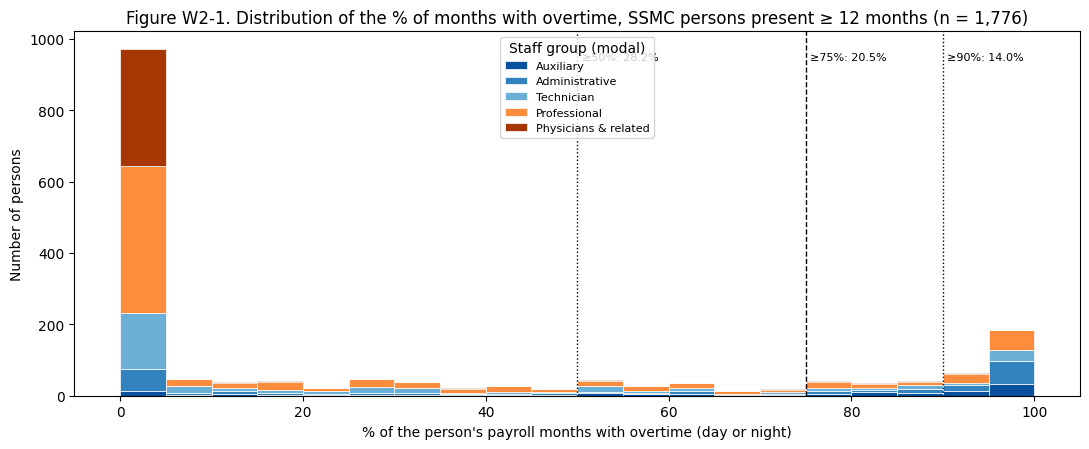

Persons at 0% of months: 922 (51.9%) | at 100%: 117 (6.6%) | between 50% and 90%: 253


In [17]:
#FIGURE W2-1: DISTRIBUTION OF THE KPI VARIABLE
fig, ax = plt.subplots(figsize=(11, 4.6))
bins = np.arange(0, 105, 5)
ax.hist([base.loc[base["staff_group"] == g, "pct_months_ot"] for g in GROUP_ORDER], bins=bins, stacked=True,
        color=[GROUP_COLOR[g] for g in GROUP_ORDER], label=GROUP_ORDER, edgecolor="white", linewidth=0.5)
for u, ls in zip([50, 75, 90], [":", "--", ":"]):
    share = (base["pct_months_ot"] >= u).mean() * 100
    ax.axvline(u, color="black", linestyle=ls, linewidth=1)
    ax.text(u + 0.5, ax.get_ylim()[1] * 0.92, f"≥{u}%: {share:.1f}%", fontsize=8)
ax.set_xlabel("% of the person's payroll months with overtime (day or night)")
ax.set_ylabel("Number of persons")
ax.set_title(f"Figure W2-1. Distribution of the % of months with overtime, SSMC persons present ≥ {MIN_MONTHS} months "
             f"(n = {len(base):,})")
ax.legend(title="Staff group (modal)", fontsize=8, loc="upper center")
plt.tight_layout()
plt.savefig(DATA_DIR / "fig_w2_b1_distribution_persistence.png", dpi=150)
plt.show()

print("Persons at 0% of months:", (base["pct_months_ot"] == 0).sum(), f"({(base['pct_months_ot'] == 0).mean():.1%})",
      "| at 100%:", (base["pct_months_ot"] == 100).sum(), f"({(base['pct_months_ot'] == 100).mean():.1%})",
      "| between 50% and 90%:", base["pct_months_ot"].between(50, 90, inclusive="left").sum())

### B.4 Figure W2-2 (relationship): persistence and overtime weight across positions

Positions are generic functions shared across staff groups (for example, *APOYO ADMINISTRATIVO* exists among administrative and professional staff, C1 §9), so the segment is **staff group × modal position**. Only segments with at least 20 persons in the persistence base are shown (C1 §9 rule). The weight excludes August 2025. The person-level association repeats the C1 Spearman correlation with the corrected data.

,persons,persistent,staff_group,persistence_%,median_weight_%
segment,,,,,
Auxiliary | CONDUCTOR,97,53,Auxiliary,54.600,24.900
Administrative | APOYO ADMINISTRATIVO,204,91,Administrative,44.600,13.400
Administrative | SECRETARIA,29,11,Administrative,37.900,9.400
Professional | ATENCION CLINICA,370,96,Professional,25.900,11.900
Technician | ATENCION CLINICA,323,57,Technician,17.600,15.700
Physicians & related | ATENCION CLINICA MEDICA,138,9,Physicians & related,6.500,21.400
Professional | APOYO ADMINISTRATIVO,276,16,Professional,5.800,7.500
Professional | JEFE DE DEPARTAMENTO,24,1,Professional,4.200,20.700
Physicians & related | QUIMICO FARMACEUTICO,22,0,Physicians & related,0.000,NaN


Spearman across 11 segments: 0.14 | across 848 persons with OT: 0.57
Within staff group (persons): {'Auxiliary': 0.7, 'Administrative': 0.59, 'Technician': 0.58, 'Professional': 0.57, 'Physicians & related': 0.2}


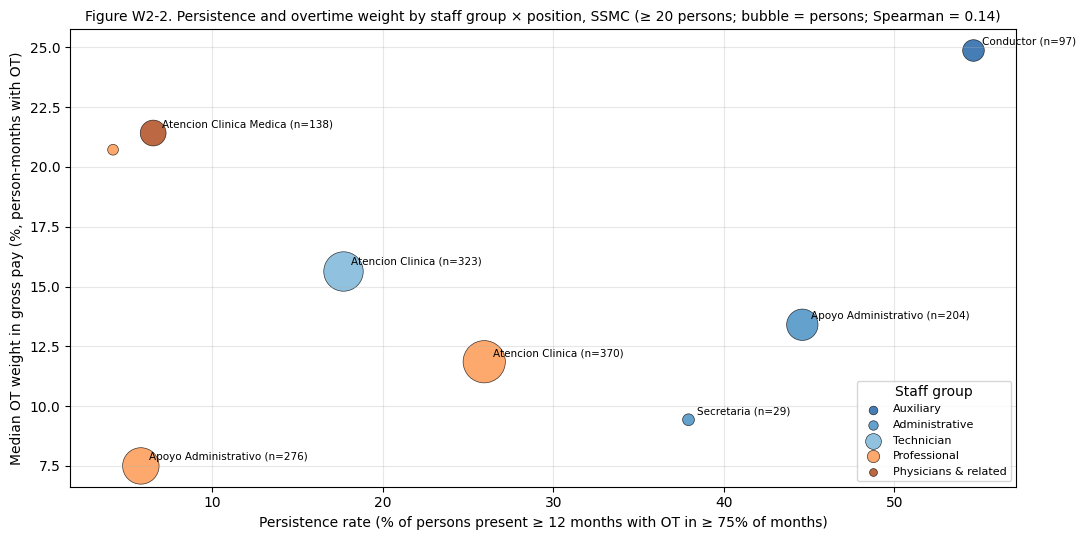

In [18]:
#FIGURE W2-2: PERSISTENCE VS WEIGHT BY STAFF GROUP × POSITION
modal_position = pm.groupby("person_id")["position"].agg(lambda s: s.mode().iloc[0])
segment_of = per_person["staff_group"] + " | " + modal_position.reindex(per_person.index)
base = base.assign(segment=segment_of.reindex(base.index))
person_weight = wb.groupby("person_id")["ot_weight"].median()

positions = base.groupby("segment").agg(persons=("persistent", "size"), persistent=("persistent", "sum"),
                                        staff_group=("staff_group", "first"))
positions = positions[positions["persons"] >= MIN_POSITION_PERSONS].copy()
positions["persistence_%"] = positions["persistent"] / positions["persons"] * 100
positions["median_weight_%"] = wb.groupby(wb["person_id"].map(segment_of))["ot_weight"].median().reindex(positions.index)
positions = positions.sort_values("persistence_%", ascending=False)
display(positions.round(1))

rho_pos = positions["persistence_%"].corr(positions["median_weight_%"], method="spearman")
with_w = base.join(person_weight.rename("median_weight"), how="inner")
rho_person = with_w["pct_months_ot"].corr(with_w["median_weight"], method="spearman")
rho_within = with_w.groupby("staff_group")[["pct_months_ot", "median_weight"]].apply(
    lambda d: d["pct_months_ot"].corr(d["median_weight"], method="spearman")).reindex(GROUP_ORDER)
print(f"Spearman across {len(positions)} segments: {rho_pos:.2f} | across {len(with_w)} persons with OT: {rho_person:.2f}")
print("Within staff group (persons):", rho_within.round(2).to_dict())

fig, ax = plt.subplots(figsize=(11, 5.5))
for g in GROUP_ORDER:
    d = positions[positions["staff_group"] == g]
    ax.scatter(d["persistence_%"], d["median_weight_%"], s=d["persons"] * 2.5, color=GROUP_COLOR[g], alpha=0.75,
               edgecolor="black", linewidth=0.5, label=g)
for name, r in positions.dropna(subset=["median_weight_%"]).head(7).iterrows():
    ax.annotate(f"{name.split(' | ')[1].title()[:26]} (n={r['persons']})", (r["persistence_%"], r["median_weight_%"]),
                fontsize=7.5, xytext=(6, 4), textcoords="offset points")
ax.set_xlabel(f"Persistence rate (% of persons present ≥ {MIN_MONTHS} months with OT in ≥ {PERSISTENCE_THRESHOLD}% of months)")
ax.set_ylabel("Median OT weight in gross pay (%, person-months with OT)")
ax.set_title(f"Figure W2-2. Persistence and overtime weight by staff group × position, SSMC (≥ {MIN_POSITION_PERSONS} persons; "
             f"bubble = persons; Spearman = {rho_pos:.2f})", fontsize=10)
ax.legend(title="Staff group", fontsize=8, markerscale=0.4)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DATA_DIR / "fig_w2_b2_persistence_weight_position.png", dpi=150)
plt.show()

### B.5 Figure W2-3 (over time, by segment): monthly overtime frequency by staff group

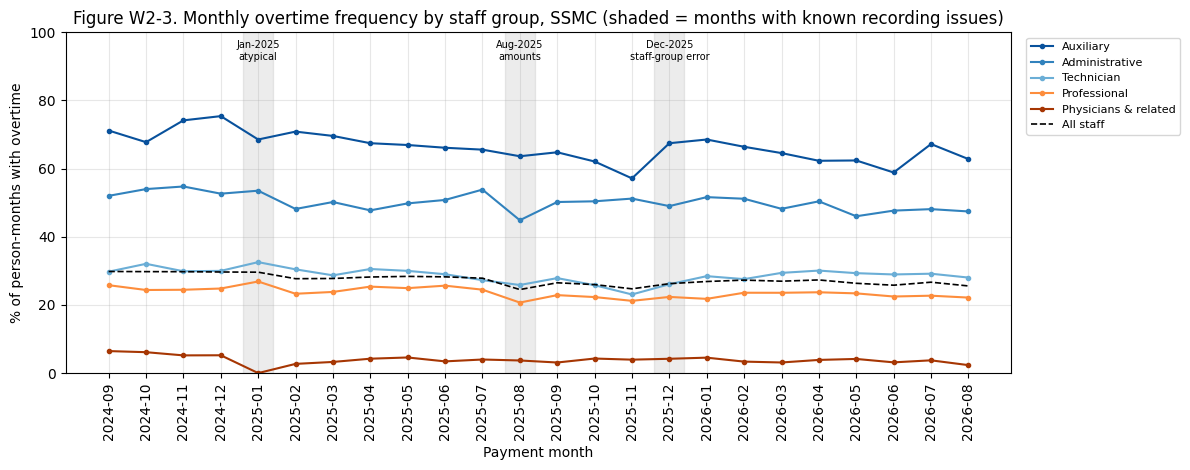

Months in which the staff-group ordering differs from the overall ordering: 0 of 24
Frequency by year (Jan-2025 excluded):


yr,Year 1,Year 2,change_pp
staff_group_modal,,,
Auxiliary,69.000,63.700,-5.200
Administrative,50.800,49.300,-1.500
Technician,29.400,27.800,-1.600
Professional,24.300,22.700,-1.600
Physicians & related,4.400,3.700,-0.800


In [19]:
#FIGURE W2-3: MONTHLY FREQUENCY BY STAFF GROUP
freq_month = pm.pivot_table(index="period", columns="staff_group_modal", values="has_ot", aggfunc="mean").reindex(columns=GROUP_ORDER) * 100
periods = list(freq_month.index)
fig, ax = plt.subplots(figsize=(12, 4.8))
for g in GROUP_ORDER:
    ax.plot(periods, freq_month[g], marker="o", markersize=3, color=GROUP_COLOR[g], label=g)
ax.plot(periods, pm.groupby("period")["has_ot"].mean() * 100, color="black", linestyle="--", linewidth=1.2, label="All staff")
for p, lab in [("2025-01", "Jan-2025\natypical"), ("2025-08", "Aug-2025\namounts"), ("2025-12", "Dec-2025\nstaff-group error")]:
    i = periods.index(p)
    ax.axvspan(i - 0.4, i + 0.4, color="grey", alpha=0.15)
    ax.text(i, 92, lab, ha="center", fontsize=7)
ax.set_ylim(0, 100)
ax.set_xlabel("Payment month")
ax.set_ylabel("% of person-months with overtime")
ax.set_title("Figure W2-3. Monthly overtime frequency by staff group, SSMC (shaded = months with known recording issues)")
ax.tick_params(axis="x", rotation=90)
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DATA_DIR / "fig_w2_b3_monthly_frequency_group.png", dpi=150)
plt.show()

rank_by_month = freq_month.rank(axis=1, ascending=False)
print("Months in which the staff-group ordering differs from the overall ordering:",
      int((rank_by_month != freq_month.mean().rank(ascending=False)).any(axis=1).sum()), "of", len(freq_month))
yr = pm.assign(yr=np.where(pm["period"] <= FEATURE_END, "Year 1", "Year 2"))
yr = yr[~yr["flag_atypical_month"]].pivot_table(index="staff_group_modal", columns="yr", values="has_ot", aggfunc="mean").reindex(GROUP_ORDER) * 100
yr["change_pp"] = yr["Year 2"] - yr["Year 1"]
print("Frequency by year (Jan-2025 excluded):")
yr.round(1)

### B.6 Figure W2-4 (comparison): is the SSMC pattern specific to the SSMC?

Same KPI definitions applied to the six Metropolitan services over their **common window** (November 2024 – August 2026, 22 months). The full comparison and its quality checks are in `EDA2.ipynb`.

Common window: 2024-11 to 2026-08 (22 months)


,persons_12m,persistence_%,ot_frequency_%,median_weight_%,rank_persistence
service,,,,,
Centro,1747.000,20.100,27.200,14.600,3.000
Norte,604.000,21.900,26.300,10.800,2.000
Oriente,1795.000,7.600,17.400,7.900,6.000
Occidente,1895.000,17.000,25.600,10.200,4.000
Sur,1540.000,22.700,30.300,12.400,1.000
SurOriente,1734.000,15.300,21.600,4.800,5.000
All services,9315.000,16.700,24.400,9.400,NaN


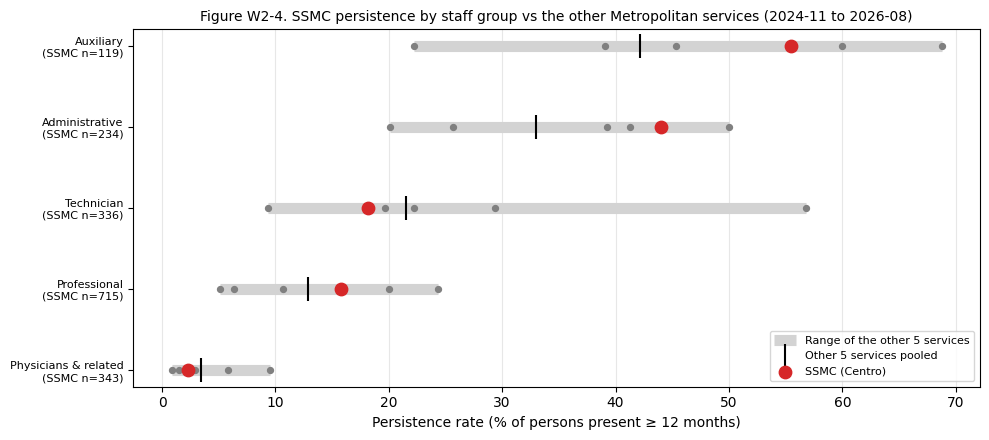

Persistence by staff group (%): SSMC vs the other five services


,SSMC,other 5 pooled,min of other 5,max of other 5,SSMC rank (of 6)
staff_group,,,,,
Auxiliary,55.500,42.200,22.200,68.800,3.000
Administrative,44.000,33.000,20.100,50.000,2.000
Technician,18.200,21.500,9.400,56.800,5.000
Professional,15.800,12.900,5.100,24.400,3.000
Physicians & related,2.300,3.500,0.900,9.500,4.000


In [20]:
#B.6 COMMON-WINDOW KPIs FOR ALL SERVICES
periods_by_service = payroll.groupby("service")["period"].apply(set)
WINDOW = sorted(set.intersection(*periods_by_service))
pm_w = build_person_months(payroll[payroll["period"].isin(WINDOW)])
per_w = (pm_w.groupby(["service", "person_id"])
             .agg(staff_group=("staff_group_modal", "first"), months=("period", "nunique"), ot_months=("has_ot", "sum"))
             .reset_index())
per_w = per_w[per_w["months"] >= MIN_MONTHS]
per_w["persistent"] = per_w["ot_months"] / per_w["months"] * 100 >= PERSISTENCE_THRESHOLD
print(f"Common window: {WINDOW[0]} to {WINDOW[-1]} ({len(WINDOW)} months)")

svc_kpi = pd.DataFrame({
    "persons_12m": per_w.groupby("service").size(),
    "persistence_%": per_w.groupby("service")["persistent"].mean() * 100,
    "ot_frequency_%": pm_w.groupby("service")["has_ot"].mean() * 100,
    "median_weight_%": pm_w[pm_w["has_ot"] & (pm_w["gross_pay"] > 0)].groupby("service")["ot_weight"].median(),
}).reindex(SERVICES)
svc_kpi.loc["All services"] = [len(per_w), per_w["persistent"].mean() * 100, pm_w["has_ot"].mean() * 100,
                               pm_w.loc[pm_w["has_ot"] & (pm_w["gross_pay"] > 0), "ot_weight"].median()]
svc_kpi["rank_persistence"] = svc_kpi["persistence_%"].drop("All services").rank(ascending=False)
display(svc_kpi.round(1))

grp = per_w.pivot_table(index="staff_group", columns="service", values="persistent", aggfunc="mean").reindex(index=GROUP_ORDER, columns=SERVICES) * 100
grp_n = per_w.pivot_table(index="staff_group", columns="service", values="persistent", aggfunc="size").reindex(index=GROUP_ORDER, columns=SERVICES)
pooled_others = per_w[per_w["service"] != ANALYSIS_SERVICE].groupby("staff_group")["persistent"].mean().reindex(GROUP_ORDER) * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(GROUP_ORDER))[::-1]
others = grp.drop(columns=ANALYSIS_SERVICE)
ax.hlines(y, others.min(axis=1), others.max(axis=1), color="lightgrey", linewidth=8, label="Range of the other 5 services")
for s in others.columns:
    ax.scatter(others[s], y, color="grey", s=18, zorder=3)
ax.scatter(pooled_others, y, marker="|", color="black", s=300, zorder=4, label="Other 5 services pooled")
ax.scatter(grp[ANALYSIS_SERVICE], y, color="#d62728", s=80, zorder=5, label="SSMC (Centro)")
ax.set_yticks(y)
ax.set_yticklabels([f"{g}\n(SSMC n={int(grp_n.loc[g, ANALYSIS_SERVICE])})" for g in GROUP_ORDER], fontsize=8)
ax.set_xlabel(f"Persistence rate (% of persons present ≥ {MIN_MONTHS} months)")
ax.set_title(f"Figure W2-4. SSMC persistence by staff group vs the other Metropolitan services ({WINDOW[0]} to {WINDOW[-1]})", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(DATA_DIR / "fig_w2_b4_ssmc_vs_services.png", dpi=150)
plt.show()

print("Persistence by staff group (%): SSMC vs the other five services")
pd.DataFrame({"SSMC": grp[ANALYSIS_SERVICE], "other 5 pooled": pooled_others,
              "min of other 5": others.min(axis=1), "max of other 5": others.max(axis=1),
              "SSMC rank (of 6)": grp.rank(axis=1, ascending=False)[ANALYSIS_SERVICE]}).round(1)

### B.7 Interpretation of the revised EDA

**What the figures show (observations)**
- **Denominators (B.1).** The persistence rate is 20.5% = 364 / 1,776 persons; frequency is 27.4% = 11,805 / 43,120 person-months; the weight is a median over 11,802 person-months. Units differ (persons vs person-months), so the three KPIs must not be added or compared directly. In the yearly windows (≥ 6 months present) persistence goes from 24.1% to 21.2%.
- **Rate vs volume (B.1).** The intervals of auxiliary (55.4%, 46.5–63.9) and administrative staff (44.8%, 38.6–51.1) do not overlap with technicians (18.4%), professionals (16.3%) or physicians (2.6%). However, **professionals contribute the largest number of persistent persons (118, 32.4%)**: a lower rate on a large group. Ranking by rate alone would miss them.
- **Distribution (Figure W2-1).**
  - The KPI variable is U-shaped: 922 persons (51.9%) never received overtime in their months, 117 (6.6%) received it every month, and only 253 lie between 50% and 90%.
  - The KPI therefore identifies a distinct minority. The threshold moves the level (28.2%, 20.5%, 14.0% at 50/75/90%), but not which persons dominate the right tail: auxiliary, administrative and some professionals.
- **Relationship (Figure W2-2).**
  - Drivers (*conductor*, 54.6% persistent, median weight 24.9%) are extreme on both axes, followed by administrative support (44.6%).
  - Clinical-care professionals (25.9%, n = 370) are the largest single source of persistent persons (96).
  - Across segments the association is weak (Spearman 0.14), because physicians combine high weight (21.4%) with low persistence (6.5%). Within staff groups, persons who receive overtime more often also have a higher weight (0.57–0.70).
- **Over time (Figure W2-3).**
  - The staff-group ordering is the same in all 24 months, so the concentration does not depend on any single month or on the flagged months.
  - Frequency fell in every staff group between years (January 2025 excluded); the largest fall was among auxiliary staff (−5.2 points).
  - The December 2025 staff-group error does not show because the modal group is used.
- **Comparison (Figure W2-4).** The SSMC is above the other services pooled for auxiliary (55.5% vs 42.2%), administrative (44.0% vs 33.0%) and professional staff (15.8% vs 12.9%), and below for technicians (18.2% vs 21.5%) and physicians. In every group, other services lie both above and below the SSMC.

**What the figures do not show (limitations)**
- They describe **payments**. A paid hour may belong to an earlier month (C4b), and no figure shows hours actually worked, authorised staffing or vacancies.
- They show **associations**. Staff group and position are not assigned at random, and there is no counterfactual (what overtime would be with more staff). In the terms of the A/B-testing class, a causal claim such as "hiring drivers would reduce overtime" needs an intervention or a credible comparison group, which this payroll does not provide.
- Driver persistence is compatible with three mechanisms that these data cannot separate: 24/7 shift design, vacancies, or authorisation practice.
- The benchmark covers only Metropolitan services and only the *contrata* payroll. Recording practices differ between services (EDA2 §2).

**Revised conclusions (see A.3)**
- The level of persistence is not exceptional for the network; its concentration in auxiliary and administrative staff is structural, and its intensity is high.
- The person-level relationship between persistence and weight holds within staff groups only.
- The yearly decline is a network-wide pattern without an identified cause.

**Managerial recommendation (labelled as such).** Use the staff group × position ranking as a **review list**, not as evidence of understaffing:
- review drivers and administrative support first, because of their rate;
- review clinical-care professionals next, because of their volume of persistent persons.

Each review should obtain the authorised staffing and shift design for the position.

## D. Sampling and representativeness

Module 3 of the semester masterclass separates three questions that are not interchangeable:
1. **Sampling:** which units entered the dataset from the target population?
2. **Data availability:** is this a sample, or all records that happened to be published?
3. **Splitting:** which rows fit, tune and evaluate a model? (Section F)

### D.1 Populations

| Level | Definition |
|---|---|
| **Target population** | Fixed-term (*contrata*) staff paid by the SSMC whose staffing the decision would affect, now and in the near future |
| **Observed population** | Persons listed in the SSMC contrata payroll published under Active Transparency, September 2024 – August 2026, identified by name: 44,777 contract-month records, 2,430 persons |
| **Analytical dataset** | 43,120 person-months (frequency and weight KPIs). For the persistence KPI: the 1,776 persons present ≥ 12 months |

**How records were selected.** This is **not a probability sample**. Every published monthly file was downloaded, so the data are a census of what the SSMC publishes. Selection happens through *what is published* and through the analytical rule of ≥ 12 months. The masterclass warning applies: *all available records ≠ the population relevant to every future decision*.

**Plausible sources of sampling or coverage bias:**
1. **Contract-type coverage (coverage bias).** Only *contrata* staff are published in this file. Permanent (*planta*), fee-based (*honorarios*) and Labor Code staff, who may also cover shifts, are not observed.
2. **Tenure selection (selection bias).** Short-tenure and replacement staff are excluded from the persistence denominator. D.2 shows that they differ.
3. **Measurement.** The payroll records *paid* hours in the *payment* month, not hours worked in that month (regularisations of earlier months; C4b).
4. **Identity.** Persons are linked by name: homonyms are merged and spelling changes split a person.
5. **Generalisation to other services and periods.** The SSMC is one of six Metropolitan services, with different levels and recording practices (B.6, EDA2). Its 24 months include a regulatory change (Dictamen E121666, July 2025).

In [21]:
#D.2 OBSERVED VS ANALYTICAL POPULATION
print(f"Persons in and out of the persistence base (≥ {MIN_MONTHS} months):")
display(per_person.groupby("in_base").agg(persons=("months", "size"), median_months=("months", "median"),
                                          mean_pct_months_ot=("pct_months_ot", "mean"),
                                          share_with_any_ot=("ot_months", lambda s: (s > 0).mean() * 100)))
print("Staff-group composition (% of persons):")
display(pd.crosstab(per_person["staff_group"], per_person["in_base"], normalize="columns")
          .reindex(GROUP_ORDER).mul(100).round(1))
print("Persons present < 12 months by number of months in the payroll:")
display(per_person.loc[~per_person["in_base"], "months"].describe().round(1).to_frame().T)

def compute_kpis(t):
    per = t.groupby("person_id").agg(months=("period", "nunique"), ot_months=("has_ot", "sum"))
    base_ = per[per["months"] >= MIN_MONTHS]
    persistent = base_["ot_months"] / base_["months"] * 100 >= PERSISTENCE_THRESHOLD
    return pd.Series({
        "person_months": len(t),
        "persons": len(per),
        "persons_12m": len(base_),
        "persistent": persistent.sum(),
        "persistence_rate_%": persistent.mean() * 100,
        "ot_frequency_%": t["has_ot"].mean() * 100,
        "median_ot_weight_%": t.loc[t["has_ot"] & (t["gross_pay"] > 0), "ot_weight"].median(),
    })

print(f"Coverage across services (common window {WINDOW[0]} to {WINDOW[-1]}; from B.6):")
svc_kpi.round(1)

Persons in and out of the persistence base (≥ 12 months):


,persons,median_months,mean_pct_months_ot,share_with_any_ot
in_base,,,,
False,654,4.000,17.371,24.006
True,1776,24.000,27.785,48.086


Staff-group composition (% of persons):


in_base,False,True
staff_group,,
Auxiliary,7.800,6.800
Administrative,15.700,13.500
Technician,21.300,19.300
Professional,37.300,40.800
Physicians & related,17.900,19.700


Persons present < 12 months by number of months in the payroll:


,count,mean,std,min,25%,50%,75%,max
months,654.000,4.800,3.100,1.000,2.000,4.000,7.000,11.000


Coverage across services (common window 2024-11 to 2026-08; from B.6):


,persons_12m,persistence_%,ot_frequency_%,median_weight_%,rank_persistence
service,,,,,
Centro,1747.000,20.100,27.200,14.600,3.000
Norte,604.000,21.900,26.300,10.800,2.000
Oriente,1795.000,7.600,17.400,7.900,6.000
Occidente,1895.000,17.000,25.600,10.200,4.000
Sur,1540.000,22.700,30.300,12.400,1.000
SurOriente,1734.000,15.300,21.600,4.800,5.000
All services,9315.000,16.700,24.400,9.400,NaN


### D.3 Reproducible 25% subsample

The persistence KPI is defined per **person** over months, so the sampling unit is the person and all of their months are kept. Sampling rows (person-months) would cut each person's history and change who reaches 12 months; this is shown as a contrast.

- **Stratified sample:** 25% of persons within each modal staff group (`SEED`), proportional allocation. With proportional allocation the sample is self-weighting ($W_h = N_h/N$), so no reweighting is needed.
- **Comparison:** persistence rate (KPI), OT frequency, OT weight and staff-group proportions against the complete dataset.
- **Sampling variability:** the stratified and simple random person samples are repeated with 500 fixed seeds, to show the range a single 25% sample can produce (sampling variability, not bias).

In [22]:
#D.3 STRATIFIED 25% PERSON SAMPLE
FRAC = 0.25
sample_ids = per_person.groupby("staff_group", group_keys=False).sample(frac=FRAC, random_state=SEED).index
pm_sample = pm[pm["person_id"].isin(sample_ids)]
pm_row_sample = pm.sample(frac=FRAC, random_state=SEED)          # contrast: naive row sample

comparison = pd.DataFrame({
    "complete": compute_kpis(pm),
    "stratified 25% persons": compute_kpis(pm_sample),
    "naive 25% rows": compute_kpis(pm_row_sample),
})
comparison["difference_stratified"] = comparison["stratified 25% persons"] - comparison["complete"]
display(comparison.round(1))

segment = pd.DataFrame({
    "complete": per_person["staff_group"].value_counts(normalize=True),
    "stratified 25% persons": per_person.loc[sample_ids, "staff_group"].value_counts(normalize=True),
    "simple 25% persons": per_person.sample(frac=FRAC, random_state=SEED)["staff_group"].value_counts(normalize=True),
}).reindex(GROUP_ORDER).mul(100)
segment["difference_stratified_pp"] = segment["stratified 25% persons"] - segment["complete"]
segment["difference_simple_pp"] = segment["simple 25% persons"] - segment["complete"]
print("Staff-group proportions (% of persons):")
segment.round(2)

,complete,stratified 25% persons,naive 25% rows,difference_stratified
person_months,43120.000,10777.000,10780.000,-32343.000
persons,2430.000,608.000,2179.000,-1822.000
persons_12m,1776.000,449.000,12.000,-1327.000
persistent,364.000,105.000,1.000,-259.000
persistence_rate_%,20.500,23.400,8.300,2.900
ot_frequency_%,27.400,30.400,27.500,3.000
median_ot_weight_%,14.600,14.700,14.500,0.100


Staff-group proportions (% of persons):


,complete,stratified 25% persons,simple 25% persons,difference_stratified_pp,difference_simple_pp
staff_group,,,,,
Auxiliary,7.080,7.070,7.070,-0.010,-0.010
Administrative,14.070,14.140,16.450,0.070,2.370
Technician,19.790,19.740,19.900,-0.060,0.110
Professional,39.840,39.800,36.350,-0.030,-3.490
Physicians & related,19.220,19.240,20.230,0.030,1.010


,count,mean,std,min,2.5%,50%,97.5%,max
stratified,500.000,20.450,1.650,15.400,17.190,20.450,23.500,24.830
simple,500.000,20.570,1.530,15.620,17.650,20.570,23.800,25.870


Seed-42 stratified sample: 23.4% (percentile 97 of the 500 draws)


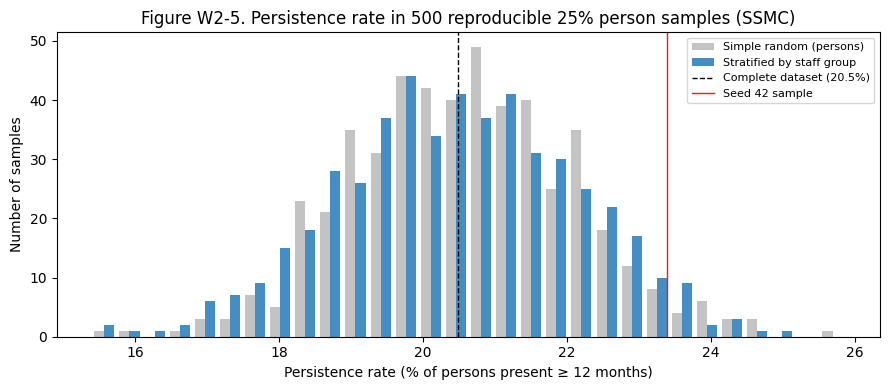

In [23]:
#D.3 SAMPLING VARIABILITY OVER 500 FIXED SEEDS
def persistence_rate(ids):
    b = per_person.loc[ids]
    b = b[b["in_base"]]
    return (b["pct_months_ot"] >= PERSISTENCE_THRESHOLD).mean() * 100

draws = pd.DataFrame({
    "stratified": [persistence_rate(per_person.groupby("staff_group", group_keys=False).sample(frac=FRAC, random_state=s).index)
                   for s in range(500)],
    "simple": [persistence_rate(per_person.sample(frac=FRAC, random_state=s).index) for s in range(500)],
})
full_rate = persistence_rate(per_person.index)
display(draws.describe(percentiles=[0.025, 0.5, 0.975]).T.round(2))
print(f"Seed-{SEED} stratified sample: {persistence_rate(sample_ids):.1f}% "
      f"(percentile {(draws['stratified'] < persistence_rate(sample_ids)).mean() * 100:.0f} of the 500 draws)")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist([draws["simple"], draws["stratified"]], bins=30, label=["Simple random (persons)", "Stratified by staff group"],
        color=["#bdbdbd", "#3182bd"], alpha=0.9)
ax.axvline(full_rate, color="black", linestyle="--", linewidth=1, label=f"Complete dataset ({full_rate:.1f}%)")
ax.axvline(persistence_rate(sample_ids), color="#d62728", linewidth=1, label=f"Seed {SEED} sample")
ax.set_title("Figure W2-5. Persistence rate in 500 reproducible 25% person samples (SSMC)")
ax.set_xlabel(f"Persistence rate (% of persons present ≥ {MIN_MONTHS} months)")
ax.set_ylabel("Number of samples")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(DATA_DIR / "fig_w2_d_sampling_variability.png", dpi=150)
plt.show()

**Observations (Section D)**

- **Observed vs analytical population (D.2).**
  - The 654 persons excluded from the persistence base (26.9% of persons, median 4 months in the payroll) are similar in staff-group composition to the base, but they receive overtime much less: 24.0% ever received it (48.1% in the base), and they had overtime in 17.4% of their months on average (27.8% in the base).
  - The difference is about **tenure**, not staff mix. The KPI is conditional on tenure and would be lower for all contrata staff (selection bias, item 2 of D.1).
- **Coverage (D.2, B.6).** The same KPI ranges from 7.6% to 22.7% across the six services. The SSMC (20.1% in the common window) cannot stand for the network's level.
- **Reproducible 25% stratified sample (D.3).**
  - Staff-group proportions match the complete data within 0.07 points; a simple random sample of persons deviates up to 3.5 points (professionals).
  - The KPI in the seed-42 sample is **23.4% vs 20.5%** (+2.9 points), and frequency 30.4% vs 27.4%. This particular sample sits at the 97th percentile of the 500 draws: a single sample can be reproducible and still unlucky.
  - Over 500 seeds, 95% of stratified samples fall between 17.2% and 23.5% (SD 1.65 points), with no precision gain over simple random sampling (SD 1.53). Stratifying on staff group fixes composition, but most of the variation is within groups, and the ≥ 12-month base is not itself stratified.
  - The median weight is stable (14.7% vs 14.6%).
- **Naive row sample.** Sampling 25% of person-months leaves only 12 persons with ≥ 12 months and gives 8.3%. This shows the sampling unit must match the KPI unit (the person).
### D.4 Why a train/test split is not evidence of representativeness

A train/test split divides the **observed** data into two parts drawn from the same source. If both parts look alike, that only shows the split was done consistently. It says nothing about the persons and contract types that never entered the file: *planta* and *honorarios* staff, other services, or staff with fewer than 12 months.

Any coverage bias in the source is copied into both train and test, so agreement between them cannot reveal it. The masterclass example makes the same point: "if rural deliveries never enter the dataset, both the training set and the test set will exclude them."

D.3 illustrates this: random persons from the SSMC reproduce the SSMC rate (about 20%) with tight variability. Yet the same KPI ranges from 7.6% to 22.7% across the other Metropolitan services (B.6), so a precise estimate of the observed population is not an estimate of a wider target. Representativeness has to be argued by comparing the observed population with the target population (D.1–D.2, B.6), not by splitting.

## E. Leakage audit

### E.1 Decision time, data flow and legitimacy of a predictive use

The project is **descriptive**. No model is fitted, and none is invented to satisfy the assignment. This section assesses whether the **future predictive use proposed in C1 §10** would be legitimate, and what information it could use.

- **Decision time:** end of September 2025, when the HR unit plans the staffing review for the coming year.
- **Prediction:** whether a person will be a persistent overtime user (≥ 75% of months with overtime) between **September 2025 and August 2026**.
- **Information available at that moment:** payroll files up to **August 2025**. Files are published about one month later, so the September 2025 file is not yet available.
- **Legitimacy.** A prediction is legitimate only as a **screening aid to decide where to review staffing** (positions and units), not to judge or sanction individuals. Names are personal data published under Law 20.285 for transparency, not for profiling, so any operational use should aggregate predictions by position before acting.

**Data flow:** authorisation → work → attendance record → pay calculation → payroll → monthly publication (≈ 1-month lag) → download.

| Variable | Available at decision time? | Note |
|---|---|---|
| Staff group, position, grade, entitlement in year 1 | Yes | Use year-1 values only (modal over Sep-2024 – Aug-2025) |
| % of months with OT, median OT hours and weight in year 1 | Yes | Computed only from year-1 person-months |
| Night share of OT hours, replacement mention in year 1 | Yes | Same |
| Modal staff group / position over the 24 months (C1) | **No** | Includes year-2 months (and the Dec-2025 error) |
| % of months with OT over the 24 months (C1 persistence variable) | **No** | Half of its months are the target period |
| Extreme-hours limit and atypical-month flags computed on 24 months | **No** | Learned from data that include the target period |
| Any year-2 value | **No** | Defines the target |

In [24]:
#E.2 EVIDENCE FOR EACH LEAKAGE RISK
y1 = pm[pm["period"].between(FEATURE_START, FEATURE_END)]
y2 = pm[pm["period"].between(TARGET_START, TARGET_END)]

per_y1 = y1.groupby("person_id").agg(months_y1=("period", "nunique"), pct_y1=("has_ot", "mean"))
per_y2 = y2.groupby("person_id").agg(months_y2=("period", "nunique"), pct_y2=("has_ot", "mean"))
per_full = pm.groupby("person_id").agg(pct_full=("has_ot", "mean"))
both = per_y1.join(per_y2, how="inner").join(per_full)
both = both[(both["months_y1"] >= MIN_MONTHS_WINDOW) & (both["months_y2"] >= MIN_MONTHS_WINDOW)]
both["target"] = both["pct_y2"] * 100 >= PERSISTENCE_THRESHOLD

print("R1 · Target-derived variable")
print("  Share of the 24-month window that belongs to the target period:",
      round(pm["period"].between(TARGET_START, TARGET_END).mean() * 100, 1), "% of person-months")
print("  Correlation with the target: full-period % months with OT =", round(both["pct_full"].corr(both["target"].astype(float)), 3),
      "| year-1 % months with OT =", round(both["pct_y1"].corr(both["target"].astype(float)), 3))

print("\nR2 · Future information in 'static' attributes")
modal_y1 = y1.groupby("person_id")["staff_group"].agg(lambda s: s.mode().iloc[0])
modal_full = pm.groupby("person_id")["staff_group_modal"].first()
pos_y1 = y1.groupby("person_id")["position"].agg(lambda s: s.mode().iloc[0])
pos_full = pm.groupby("person_id")["position"].agg(lambda s: s.mode().iloc[0])
ids = both.index
print("  Eligible persons whose modal staff group differs (24 months vs year 1):",
      (modal_full.reindex(ids) != modal_y1.reindex(ids)).sum(), "of", len(ids))
print("  Eligible persons whose modal position differs (24 months vs year 1):",
      (pos_full.reindex(ids) != pos_y1.reindex(ids)).sum(), "of", len(ids))
print("  Staff-group changes recorded inside the target period (e.g. Dec-2025 error):",
      changes[(changes["service"] == ANALYSIS_SERVICE) & changes["period"].between(TARGET_START, TARGET_END)].shape[0])

print("\nR3 · Repeated persons and duplicated records under a naive row split")
tr_rows, te_rows = train_test_split(pm, test_size=TEST_SIZE, random_state=SEED)
shared = set(tr_rows["person_id"]) & set(te_rows["person_id"])
print("  Test person-months whose person also appears in train:",
      round(te_rows["person_id"].isin(shared).mean() * 100, 1), "%")
print("  Persons present on both sides:", len(shared), "of", pm["person_id"].nunique())
dup_pay = pay[pay.duplicated(subset=key_cols, keep=False)]
print("  Exact duplicate contract rows in the SSMC (copies):", pay.duplicated(subset=key_cols).sum(),
      "| persons involved:", dup_pay["person_id"].nunique())

print("\nR4 · Preprocessing learned from the whole dataset")
q1_y1, q3_y1 = y1.loc[y1["has_ot"], "ot_hours"].quantile([0.25, 0.75])
print(f"  Extreme-hours limit: full period = {EXTREME_LIMIT_FULL} h | year 1 only = {q3_y1 + 1.5 * (q3_y1 - q1_y1)} h")
print("  Person-months flagged as extreme with each limit (year 1):",
      (y1["ot_hours"] > EXTREME_LIMIT_FULL).sum(), "vs", (y1["ot_hours"] > q3_y1 + 1.5 * (q3_y1 - q1_y1)).sum())
print("  Atypical/amount months found with the full series (EDA2 rule):", ATYPICAL_MONTHS + AMOUNT_MONTHS,
      "-> Aug-2025 is the last feature month")

print("\nR5 · Information from linked tables / other services")
names_centro = set(pay["name"].str.strip())
other = payroll[~is_ssmc]
print("  SSMC names that also appear in another service's payroll:", len(names_centro & set(other["name"].str.strip())))
print("  External tables joined to the analytical dataset: none")

R1 · Target-derived variable
  Share of the 24-month window that belongs to the target period: 50.7 % of person-months
  Correlation with the target: full-period % months with OT = 0.849 | year-1 % months with OT = 0.734

R2 · Future information in 'static' attributes


  Eligible persons whose modal staff group differs (24 months vs year 1): 0 of 1597
  Eligible persons whose modal position differs (24 months vs year 1): 38 of 1597
  Staff-group changes recorded inside the target period (e.g. Dec-2025 error): 440

R3 · Repeated persons and duplicated records under a naive row split
  Test person-months whose person also appears in train: 99.5 %
  Persons present on both sides: 2096 of 2430
  Exact duplicate contract rows in the SSMC (copies): 27 | persons involved: 11

R4 · Preprocessing learned from the whole dataset
  Extreme-hours limit: full period = 157.5 h | year 1 only = 165.0 h
  Person-months flagged as extreme with each limit (year 1): 298 vs 247
  Atypical/amount months found with the full series (EDA2 rule): ['2025-01', '2025-08'] -> Aug-2025 is the last feature month

R5 · Information from linked tables / other services


  SSMC names that also appear in another service's payroll: 45
  External tables joined to the analytical dataset: none


### E.3 Leakage audit table

The status is set from how the C1 pipeline was built; the **evidence** column quotes the E.2 output.

| # | Risk | Status | Evidence (E.2 / F.2) | Potential consequence | Mitigation (implemented) |
|---|---|---|---|---|---|
| R1 | **Target-derived variable:** the C1 persistence variable (% of months with OT over 24 months) contains the target period | **Present** in the C1 variables | 50.7% of the 24-month person-months belong to the target year. Correlation with the target: 0.849 for the 24-month variable vs 0.734 for the year-1 variable | A model would partly "predict" persistence from persistence itself; inflated, unusable accuracy | Features computed only from year-1 person-months; an `assert` blocks year-2 variables (F.1) |
| R2 | **Future information** in attributes that look static (modal staff group and position over 24 months; Dec-2025 staff-group error) | **Present** for position; **absent in practice** for staff group | 0 of 1,597 eligible persons change modal staff group, but 38 (2.4%) change modal position when year 2 is included; 440 staff-group changes fall inside the target year | Features would not exist at decision time; segment assignments would be inconsistent at deployment | Modal values recomputed on year 1 only |
| R3 | **Repeated persons and duplicated records** | **Present** under a row split; **absent** under the person split | Naive row split: 99.5% of test person-months belong to persons also in train (2,096 of 2,430 persons on both sides); 27 duplicate rows from 11 persons. Person split: 0 shared persons, 0 shared person-months, 0 duplicate persons on both sides (F.2) | The model memorises persons; test performance overstated | Unit = person, grouped split (F.2); duplicates stay with their person |
| R4 | **Preprocessing learned from the whole dataset:** extreme-hours limit, flagged months and the 75% threshold were set in W1/C1 after seeing all 24 months | **Present** | Extreme-hours limit 157.5 h (24 months) vs 165.0 h (year 1): 298 vs 247 year-1 person-months flagged | Test information shapes cleaning rules; the holdout is not untouched | Imputation, scaling, encoding and the extreme-hours limit re-learned on train only and refitted per fold (F.3–F.4). The 75% threshold and the Jan/Aug-2025 flags are documented as pre-W2 decisions and are not tuned further |
| R5 | **Linked tables / other services** | **Absent** for the SSMC design; **uncertain** if services are pooled | No external join. 45 SSMC names also appear in other services' payrolls | Pooling services by name could merge different persons, or split the same person across train and test | No cross-service join. If services are pooled later, group the split by name across services |
| R6 | **Publication lag** | **Absent by design** | Feature window ends August 2025; the September 2025 file is published in October | Using it would add a target month to the features | Feature window fixed in the configuration (`FEATURE_END`) |
| R7 | **Exploration already done on the full data (W1/C1)** | **Present, cannot be removed** | W1/C1 explored all 2,430 persons, including the 320 now in test | Choices already reflect test persons, so the holdout overstates independence | Holdout used once, as a robustness check only (F.5); stated as a limitation |

## F. Train/test datasets and validation plan

### F.1 Split design

Following the masterclass rule *"first understand the observational structure, then decide how to split"*:

| Structure in the data | Consequence for the split |
|---|---|
| **Time:** the decision is taken once a year with past payroll only | Features and target are **chronologically separated** (features: year 1; target: year 2) |
| **Repeated observations:** each person has up to 24 person-months (E.2 R3) | The modelling unit is the **person**, with one row each, and the split is **grouped by person**: no person can appear in both sets |
| **Target:** persistent in year 2, a binary minority class | The split is **stratified** by year-1 staff group × target, so that small groups (auxiliary, physicians) and the positive class keep their proportions. Strata with fewer than 10 persons are merged |
| **Proportions** | 80/20 train/test (`TEST_SIZE`) |
| **Internal validation** | **5-fold stratified cross-validation inside train only**; the test set is not used for any choice |
| **Eligibility** | Persons with ≥ `MIN_MONTHS_WINDOW` months in each window, so that features and target rest on enough months |

*Limitation:* only one chronological cut (year 1 → year 2) exists in 24 months, so a rolling-origin validation over several years is not possible.

In [25]:
#F.1 MODELLING TABLE (ONE ROW PER PERSON; FEATURES FROM YEAR 1 ONLY)
g1 = y1.groupby("person_id")
features = pd.DataFrame({
    "months_y1": g1["period"].nunique(),
    "staff_group_y1": g1["staff_group"].agg(lambda s: s.mode().iloc[0]),
    "position_y1": g1["position"].agg(lambda s: s.mode().iloc[0]),
    "ot_entitled_share_y1": g1["ot_entitled"].mean() * 100,
    "replacement_y1": g1["replacement"].max().astype(int),
    "pct_months_ot_y1": g1["has_ot"].mean() * 100,
    "median_ot_hours_y1": y1[y1["has_ot"]].groupby("person_id")["ot_hours"].median(),
    "median_ot_weight_y1": y1[y1["has_ot"] & (y1["gross_pay"] > 0)].groupby("person_id")["ot_weight"].median(),
    "night_share_y1": g1["night_hours"].sum() / g1["ot_hours"].sum().replace(0, np.nan) * 100,
})
# Persons without overtime in year 1 have 0 hours and 0 weight by definition (a rule, not a learned value);
# their night share is undefined and is imputed later from train only (F.3).
features[["median_ot_hours_y1", "median_ot_weight_y1"]] = features[["median_ot_hours_y1", "median_ot_weight_y1"]].fillna(0)

g2 = y2.groupby("person_id")
target = pd.DataFrame({"months_y2": g2["period"].nunique(), "pct_months_ot_y2": g2["has_ot"].mean() * 100})

model_table = features.join(target, how="inner")
eligible = model_table[(model_table["months_y1"] >= MIN_MONTHS_WINDOW) & (model_table["months_y2"] >= MIN_MONTHS_WINDOW)].copy()
eligible["target_persistent_y2"] = eligible["pct_months_ot_y2"] >= PERSISTENCE_THRESHOLD

FEATURES = ["months_y1", "staff_group_y1", "position_y1", "ot_entitled_share_y1", "replacement_y1",
            "pct_months_ot_y1", "median_ot_hours_y1", "median_ot_weight_y1", "night_share_y1"]
TARGET = "target_persistent_y2"
assert not set(FEATURES) & {"months_y2", "pct_months_ot_y2", TARGET}, "a year-2 variable is among the features"

flow = pd.Series({
    "Persons in the SSMC (24 months)": pm["person_id"].nunique(),
    "Persons in year 1": len(features),
    "Persons in year 2": len(target),
    "Persons in both years": len(model_table),
    f"Eligible (≥ {MIN_MONTHS_WINDOW} months in each year)": len(eligible),
    "Eligible and persistent in year 2": int(eligible[TARGET].sum()),
})
print(flow)
print("\nMissing values in the features:")
eligible[FEATURES].isna().sum()

Persons in the SSMC (24 months)       2430
Persons in year 1                     2111
Persons in year 2                     2149
Persons in both years                 1830
Eligible (≥ 6 months in each year)    1597
Eligible and persistent in year 2      353
dtype: int64

Missing values in the features:


months_y1                 0
staff_group_y1            0
position_y1               0
ot_entitled_share_y1      0
replacement_y1            0
pct_months_ot_y1          0
median_ot_hours_y1        0
median_ot_weight_y1       0
night_share_y1          875
dtype: int64

In [26]:
#F.2 TRAIN / TEST SPLIT AND CROSS-VALIDATION FOLDS
label = eligible[TARGET].map({True: "P", False: "N"})
strata = eligible["staff_group_y1"] + "|" + label
strata = strata.where(strata.map(strata.value_counts()) >= 10, "Other|" + label)
strata = strata.where(strata.map(strata.value_counts()) >= 2, label)          # last resort for tiny strata

train_ids, test_ids = train_test_split(eligible.index, test_size=TEST_SIZE, random_state=SEED, stratify=strata)
train = eligible.loc[train_ids].copy()
test = eligible.loc[test_ids].copy()

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
train["fold"] = -1
for k, (_, val_pos) in enumerate(skf.split(train, train[TARGET])):
    train.iloc[val_pos, train.columns.get_loc("fold")] = k

def describe_set(t):
    return pd.Series({
        "persons": len(t),
        "% of eligible": len(t) / len(eligible) * 100,
        "persistent_y2_%": t[TARGET].mean() * 100,
        **{f"% {g}": (t["staff_group_y1"] == g).mean() * 100 for g in GROUP_ORDER},
    })

sets = {"eligible": eligible, "train": train, "test": test}
sets.update({f"train fold {k} (validation)": train[train["fold"] == k] for k in range(N_FOLDS)})
pd.DataFrame({name: describe_set(t) for name, t in sets.items()}).T.round(1)

,persons,% of eligible,persistent_y2_%,% Auxiliary,% Administrative,% Technician,% Professional,% Physicians & related
eligible,1597.000,100.000,22.100,7.000,13.700,19.900,41.000,18.300
train,1277.000,80.000,22.100,7.000,13.700,19.900,41.000,18.300
test,320.000,20.000,22.200,6.900,13.800,20.000,40.900,18.400
train fold 0 (validation),256.000,16.000,22.300,6.200,12.500,19.500,41.000,20.700
train fold 1 (validation),256.000,16.000,22.300,5.900,13.700,20.300,44.100,16.000
train fold 2 (validation),255.000,16.000,22.000,6.300,14.500,18.400,42.000,18.800
train fold 3 (validation),255.000,16.000,22.000,8.600,12.200,23.100,37.600,18.400
train fold 4 (validation),255.000,16.000,22.000,8.200,15.700,18.000,40.400,17.600


In [27]:
#F.2 OVERLAP AND REPRODUCIBILITY CHECKS
train_set, test_set = set(train.index), set(test.index)
pm_train = pm[pm["person_id"].isin(train_set)]
pm_test = pm[pm["person_id"].isin(test_set)]

overlap_checks = pd.Series({
    "persons in both train and test": len(train_set & test_set),
    "train + test = eligible persons": len(train_set | test_set) == len(eligible),
    "duplicated person ids in the modelling table": eligible.index.duplicated().sum(),
    "train persons without a validation fold": (train["fold"] < 0).sum(),
    "persons in more than one validation fold": train.groupby(level=0)["fold"].nunique().gt(1).sum(),
    "test persons inside any CV fold": len(test_set & set(train.index[train["fold"] >= 0])),
    "person-months shared by train and test": len(set(pm_train.index) & set(pm_test.index)),
    "persons with exact-duplicate rows in both sets": len(set(dup_pay["person_id"]) & train_set & test_set),
    "year-2 months used in features": int(y1["period"].max() > FEATURE_END),
})
display(overlap_checks.to_frame("result"))
assert len(train_set & test_set) == 0 and (train["fold"] >= 0).all()

fingerprint = hashlib.sha256(",".join(map(str, sorted(test_set))).encode()).hexdigest()[:12]
print("Test-set fingerprint (must be identical on every run with SEED =", SEED, "):", fingerprint)

split_out = pd.concat([train.assign(set="train")[["set", "fold"]], test.assign(set="test", fold=-1)[["set", "fold"]]])
(DATA_DIR / "processed").mkdir(exist_ok=True)
split_out.rename_axis("person_id").to_csv(DATA_DIR / "processed" / "w2_split_ssmc.csv")
print("Split saved:", split_out.shape, "(person_id is a numeric id, names are not saved)")

,result
persons in both train and test,0
train + test = eligible persons,True
duplicated person ids in the modelling table,0
train persons without a validation fold,0
persons in more than one validation fold,0
test persons inside any CV fold,0
person-months shared by train and test,0
persons with exact-duplicate rows in both sets,0
year-2 months used in features,0


Test-set fingerprint (must be identical on every run with SEED = 42 ): db025253808a
Split saved: (1597, 2) (person_id is a numeric id, names are not saved)


### F.3 Preprocessing learned from training data only

Three operations learn parameters. All of them are **fitted on train and only applied** to test:
1. **Median imputation** of `night_share_y1` (undefined for persons without overtime in year 1). The value is a train statistic, never a test one.
2. **Standard scaling** of the numeric features, using the train mean and standard deviation.
3. **One-hot encoding** of staff group and position. Positions with fewer than 20 train persons, and positions never seen in train, go to an "infrequent" category.

A fourth example reuses the W1/C1 cleaning rule: the **extreme-hours limit** (Q3 + 1.5·IQR) is re-learned from train persons' year-1 person-months instead of the full 24 months.

In [28]:
#F.3 TRAIN-ONLY PREPROCESSING
NUMERIC = ["months_y1", "ot_entitled_share_y1", "pct_months_ot_y1", "median_ot_hours_y1", "median_ot_weight_y1", "night_share_y1"]
CATEGORICAL = ["staff_group_y1", "position_y1"]
BINARY = ["replacement_y1"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), CATEGORICAL),
    ("bin", "passthrough", BINARY),
])
preprocess.fit(train[FEATURES])                         # fitted once, on train only
X_train = preprocess.transform(train[FEATURES])
X_test = preprocess.transform(test[FEATURES])           # applied, never refitted

imputer = preprocess.named_transformers_["num"]["impute"]
scaler = preprocess.named_transformers_["num"]["scale"]
learned = pd.DataFrame({
    "imputation value (learned)": imputer.statistics_,
    "train median": train[NUMERIC].median().values,
    "test median (not used)": test[NUMERIC].median().values,
    "scaler mean (learned)": scaler.mean_,
    "train mean": train[NUMERIC].fillna(train[NUMERIC].median()).mean().values,
    "test mean (not used)": test[NUMERIC].fillna(train[NUMERIC].median()).mean().values,
}, index=NUMERIC)
display(learned.round(2))

n_num = len(NUMERIC)
print("Mean of scaled numeric features: train =", X_train[:, :n_num].mean(axis=0).round(3),
      "| test =", X_test[:, :n_num].mean(axis=0).round(3), "(test is not centred at 0: expected)")
night_idx = NUMERIC.index("night_share_y1")
imputed_test = test["night_share_y1"].isna()
print(f"Test persons imputed with the TRAIN median ({imputer.statistics_[night_idx]:.2f}):", imputed_test.sum(),
      f"| the test median would have been {test['night_share_y1'].median():.2f} (not used)")

encoder = preprocess.named_transformers_["cat"]
infrequent = encoder.infrequent_categories_[1]
print("Positions learned from train:", len(encoder.categories_[1]),
      "| grouped as infrequent (< 20 train persons):", 0 if infrequent is None else len(infrequent))
print("Test persons whose position never appears in train:", (~test["position_y1"].isin(encoder.categories_[1])).sum())

# Cleaning rule re-learned on train: extreme-hours limit from train persons' year-1 person-months
y1_train = y1[y1["person_id"].isin(train_set)]
q1_tr, q3_tr = y1_train.loc[y1_train["has_ot"], "ot_hours"].quantile([0.25, 0.75])
EXTREME_LIMIT_TRAIN = q3_tr + 1.5 * (q3_tr - q1_tr)
y1_test = y1[y1["person_id"].isin(test_set)]
print(f"\nExtreme-hours limit: train-only = {EXTREME_LIMIT_TRAIN} h | full 24 months (C1) = {EXTREME_LIMIT_FULL} h")
print("Test year-1 person-months above the train-only limit (rule applied, not refitted):", (y1_test["ot_hours"] > EXTREME_LIMIT_TRAIN).sum())

,imputation value (learned),train median,test median (not used),scaler mean (learned),train mean,test mean (not used)
months_y1,12.000,12.000,12.000,11.680,11.680,11.720
ot_entitled_share_y1,8.330,8.330,8.330,30.680,30.680,30.620
pct_months_ot_y1,0.000,0.000,0.000,30.140,30.140,29.770
median_ot_hours_y1,0.000,0.000,0.000,19.620,19.620,18.930
median_ot_weight_y1,0.000,0.000,0.000,6.540,6.540,6.360
night_share_y1,44.990,44.990,50.380,44.680,44.680,45.590


Mean of scaled numeric features: train = [ 0.  0. -0. -0. -0. -0.] | test = [ 0.042 -0.002 -0.009 -0.019 -0.018  0.046] (test is not centred at 0: expected)
Test persons imputed with the TRAIN median (44.99): 175 | the test median would have been 50.38 (not used)
Positions learned from train: 47 | grouped as infrequent (< 20 train persons): 38
Test persons whose position never appears in train: 4

Extreme-hours limit: train-only = 157.5 h | full 24 months (C1) = 157.5 h
Test year-1 person-months above the train-only limit (rule applied, not refitted): 48


In [29]:
#F.4 CROSS-VALIDATION: PREPROCESSING REFITTED INSIDE EACH TRAINING FOLD
fold_params = []
for k in range(N_FOLDS):
    fit_part, val_part = train[train["fold"] != k], train[train["fold"] == k]
    pipe = clone(preprocess).fit(fit_part[FEATURES])               # fold-train only
    pipe.transform(val_part[FEATURES])                             # validation fold: transform only
    num = pipe.named_transformers_["num"]
    fold_params.append({
        "fold": k,
        "fit persons": len(fit_part),
        "validation persons": len(val_part),
        "validation persistent_%": val_part[TARGET].mean() * 100,
        "night_share imputation": num["impute"].statistics_[NUMERIC.index("night_share_y1")],
        "pct_months_ot mean": num["scale"].mean_[NUMERIC.index("pct_months_ot_y1")],
        "fit/validation overlap": len(set(fit_part.index) & set(val_part.index)),
        "test persons used": len(set(fit_part.index) & test_set) + len(set(val_part.index) & test_set),
    })
pd.DataFrame(fold_params).set_index("fold").round(2)

,fit persons,validation persons,validation persistent_%,night_share imputation,pct_months_ot mean,fit/validation overlap,test persons used
fold,,,,,,,
0,1021,256,22.270,46.550,30.200,0,0
1,1021,256,22.270,45.200,29.660,0,0
2,1022,255,21.960,45.080,30.970,0,0
3,1022,255,21.960,46.180,29.830,0,0
4,1022,255,21.960,41.670,30.010,0,0


### F.5 Validation plan and treatment of test information

- **Validation.** Any future model, threshold or feature choice is compared only on the 5 training folds (F.4), with preprocessing refitted inside each fold. Following the supervised-learning class, the primary validation metric for a future classifier would be the positive-class F1 with a threshold chosen on validation, never on test.
- **Test set.** Stored in `Data/processed/w2_split_ssmc.csv` and identified by its fingerprint. It is used **once**, after every choice is frozen. It is not used to choose variables, adjust cleaning thresholds or tune a model. **No model is fitted in W2.**
- **Descriptive project.** The holdout is used here as an **independent robustness check** of the descriptive pattern: does the ranking of staff groups by year-2 persistence hold in persons not used to set the split? It is **not** a measure of predictive accuracy.
- **Limits.** W1 and C1 explored the full 24 months, including the persons now in test. The 75% threshold, the January-2025 flag and the extreme-hours rule were chosen after seeing those data, so the holdout is **not untouched**: it protects only the choices made from now on. There is only one chronological cut, so temporal stability cannot be validated, and persons are identified by name.

In [30]:
#F.5 ROBUSTNESS CHECK ON THE HOLDOUT (RUN ONCE, AFTER ALL CHOICES ARE FROZEN)
robustness = pd.DataFrame({
    "train persistent_y2_%": train.groupby("staff_group_y1")[TARGET].mean() * 100,
    "test persistent_y2_%": test.groupby("staff_group_y1")[TARGET].mean() * 100,
    "train persons": train.groupby("staff_group_y1").size(),
    "test persons": test.groupby("staff_group_y1").size(),
}).reindex(GROUP_ORDER)
robustness["test CI95"] = [f"{lo:.0f}–{hi:.0f}" for lo, hi in
                           (wilson(int(test.loc[test["staff_group_y1"] == g, TARGET].sum()), int(n))
                            for g, n in robustness["test persons"].items())]
robustness.loc["Total"] = [train[TARGET].mean() * 100, test[TARGET].mean() * 100, len(train), len(test),
                           "{:.0f}–{:.0f}".format(*wilson(int(test[TARGET].sum()), len(test)))]
print("Same staff-group ranking in train and test:",
      list(robustness["train persistent_y2_%"].drop("Total").astype(float).rank(ascending=False)) ==
      list(robustness["test persistent_y2_%"].drop("Total").astype(float).rank(ascending=False)))
robustness

Same staff-group ranking in train and test: True


,train persistent_y2_%,test persistent_y2_%,train persons,test persons,test CI95
staff_group_y1,,,,,
Auxiliary,51.111,50.000,90,22,31–69
Administrative,45.143,45.455,175,44,32–60
Technician,19.685,20.312,254,64,12–32
Professional,18.511,18.321,524,131,13–26
Physicians & related,4.274,5.085,234,59,2–14
Total,22.083,22.188,1277,320,18–27


**Observations (Section F)**

- **Counts.**
  - Of 2,430 SSMC persons, 1,830 appear in both years and 1,597 are eligible (≥ 6 months in each year); 353 of them (22.1%) are persistent in year 2.
  - Train has 1,277 persons (80.0%) and test 320 (20.0%), with persistent shares of 22.1% and 22.2% and staff-group shares within 0.1 points.
  - The five validation folds have 255–256 persons each, with 22.0%–22.3% persistent.
- **Overlap and reproducibility.** Every overlap check is zero: persons, person-months, CV folds and duplicate rows. The test-set fingerprint `db025253808a` is identical across runs with `SEED = 42`.
- **Train-only preprocessing (F.3).**
  - The night-share imputation uses the train median (44.99) for the 175 test persons without year-1 overtime. The test median (50.38) would have injected test information worth 5.4 points.
  - Scaled test means are not exactly zero, which confirms that test was transformed and not refitted.
  - 38 of 47 positions fall into the "infrequent" category, and the 4 test persons with positions unseen in train are mapped to it without refitting.
  - The train-only extreme-hours limit (157.5 h) happens to equal the C1 full-period value; the year-1 limit over all persons would be 165 h.
- **Cross-validation (F.4).** Fold parameters vary (night-share imputation 41.7–46.6), as expected when refitting inside each fold, and no test person is used.
- **Holdout robustness check (F.5).**
  - Run once: the staff-group ranking of year-2 persistence is identical in train and test, and every test rate is within 1 point of train (auxiliary 51.1% vs 50.0%, administrative 45.1% vs 45.5%).
  - Test intervals are wide (auxiliary 31–69%, n = 22), so this supports the **stability of the descriptive pattern** for persons not used to set the split, not its precision.
  - It is not a predictive-accuracy result. Because W1/C1 explored these persons, it is not a fully untouched test either.

## G. Management summary, AI-use disclosure and reproducibility

### G.1 Management summary

**What changed from C1.** We validated the payroll with 19 reproducible checks, corrected the amount parser and the cross-service loader, and benchmarked the SSMC against the other five Metropolitan health services. The C1 values did not change (20.5%, or 364 of 1,776 persons), but their scope did: the rate describes staff with at least 12 months in the payroll, not all contrata staff.

**What we can conclude.** Persistent overtime concentrates in auxiliary (55%) and administrative (45%) staff, especially drivers and administrative support. The pattern holds in every month, in an independent holdout and in all six services. The SSMC's persistence level is not exceptional (3rd of 6; 18.4% after adjusting for staff mix), but its overtime weighs more in gross pay than in any other service.

**What remains uncertain.** We cannot say why. Payroll data cannot separate staff shortages, shift design or authorisation practices, and the yearly decline occurred across the whole network.

**Next step.** Obtain authorised staffing and vacancies by position and unit, and compare the shift design for drivers and administrative support with lower-intensity services such as Oriente.

### G.2 AI-use disclosure

An AI assistant (Claude, Anthropic, through Claude Code) was used to:
- translate the EDA2 draft into English;
- refactor the loading code and draft code for the validation checks, the sampling demonstration, the split and the figures;
- draft explanatory text.

It worked only with the public Active Transparency files in the repository. The team is responsible for every result and methodological choice: KPI definition, 75% threshold, flags, split design and interpretation. The team re-ran both notebooks from top to bottom and checked that the SSMC values reproduce C1 exactly (`assert` in `EDA2.ipynb` §3.4; C.10 in this notebook). Each number quoted in the text was checked against the cell output it comes from.

### G.3 Reproducibility and traceability

- **Run:** from `Analysis/`, Kernel → Restart & Run All (about 1–2 minutes). Inputs: `../Data/*TransparenciaActiva_*.csv`. Outputs: figures `../Data/fig_w2_*.png` and the split `../Data/processed/w2_split_ssmc.csv` (numeric person ids only, no names).
- **Randomness:** `SEED = 42` for the subsample, the train/test split and the CV folds. The test-set fingerprint printed in F.2 must not change between runs.
- **Environment:** see `README.md` and `requirements.txt`.
- **Traceability:** W1/C1 work is preserved unchanged in `Analysis/EDA.ipynb` and the PDF reports. The W2 work is in this notebook and `Analysis/EDA2.ipynb`, committed to https://github.com/josenaxo/Proyecto-Business and tagged `W2`.

In [31]:
#ENVIRONMENT USED FOR THIS RUN
import sys, sklearn, matplotlib
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.7 | pandas 2.3.3 | numpy 2.3.3 | scikit-learn 1.7.2 | matplotlib 3.10.6
